In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import os

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = Path(os.environ.get("DATA_DIR", PROJECT_ROOT / "data")).resolve()
GOLD_DIR = DATA_DIR / "gold"
# Analysis outputs
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHARTS_DIR = OUTPUT_DIR / "charts"
METRICS_DIR = OUTPUT_DIR / "metrics"

# Create output directories
for directory in [OUTPUT_DIR, CHARTS_DIR, METRICS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Project root: D:\Projects\remarcable-assignment
Data directory: D:\Projects\remarcable-assignment\data


In [3]:
dim_customer = pd.read_csv(
    GOLD_DIR / "dim_customer.csv"
)

dim_item = pd.read_csv(
    GOLD_DIR / "dim_item.csv"
)

dim_vendor = pd.read_csv(
    GOLD_DIR / "dim_vendor.csv"
)

fct_purchase_order_line = pd.read_csv(
    GOLD_DIR / "fct_purchase_order_line.csv"
)

item_purchase_history = pd.read_csv(
    GOLD_DIR / "item_purchase_history.csv"
)

validated_purchase_order_lines = pd.read_csv(
    GOLD_DIR / "fct_purchase_order_line_validated.csv"
)

print("Validated records:", len(validated_purchase_order_lines))

Validated records: 8462


In [4]:
validated_purchase_order_lines["order_date"] = pd.to_datetime(
    validated_purchase_order_lines["order_date"],
    errors="coerce"
)

In [5]:
display(validated_purchase_order_lines)

,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount
0,PO-100000,CUST-A,VEND-06,2024-04-01,Closed,ITM-0431,10,0.72,7.20
1,PO-100001,CUST-B,VEND-12,2026-05-21,Closed,ITM-0220,10,2.66,26.60
2,PO-100001,CUST-B,VEND-12,2026-05-21,Closed,ITM-0426,4,26.05,104.20
3,PO-100001,CUST-B,VEND-12,2026-05-21,Closed,ITM-0612,2,4.71,9.42
4,PO-100001,CUST-B,VEND-12,2026-05-21,Closed,ITM-1015,12,4.80,57.60
...,...,...,...,...,...,...,...,...,...
8457,PO-103179,CUST-D,VEND-08,2024-02-01,Received,ITM-0230,2,2.97,5.94
8458,PO-103179,CUST-D,VEND-08,2024-02-01,Received,ITM-0306,10,0.89,8.90
8459,PO-103179,CUST-D,VEND-08,2024-02-01,Received,ITM-0517,10,42.17,421.70
8460,PO-103179,CUST-D,VEND-08,2024-02-01,Received,ITM-1018,2,4.81,9.62


In [6]:
SILVER_DIR = DATA_DIR / "silver"

purchase_orders = pd.read_csv(
    SILVER_DIR / "purchase_orders.csv"
)

itemized_purchase_orders = pd.read_csv(
    SILVER_DIR / "itemized_purchase_orders.csv"
)

items = pd.read_csv(
    SILVER_DIR / "items.csv"
)

item_pricing = pd.read_csv(
    SILVER_DIR / "item_pricing.csv"
)

In [7]:
COMPANY_A = "CUST-A"

company_a = validated_purchase_order_lines[
    validated_purchase_order_lines["customer_id"] == COMPANY_A
].copy()

print("Company A purchase lines:", len(company_a))
print("Unique purchase orders:", company_a["po_number"].nunique())
print("Unique items:", company_a["item_id"].nunique())
print("Unique vendors:", company_a["vendor_id"].nunique())

Company A purchase lines: 2315
Unique purchase orders: 820
Unique items: 122
Unique vendors: 12


In [8]:
company_a.isna().sum().to_frame("missing_values")

,missing_values
po_number,0
customer_id,0
vendor_id,0
order_date,0
status,0
item_id,0
quantity_ordered,0
unit_price_paid,10
extended_amount,10


In [9]:
missing_price_records = company_a[
    company_a["unit_price_paid"].isna()
]

display(missing_price_records)

,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount
139,PO-100053,CUST-A,VEND-04,2026-07-04,Closed,ITM-0632,6,NaN,NaN
168,PO-100066,CUST-A,VEND-10,2024-08-13,Received,ITM-0929,4,NaN,NaN
994,PO-100364,CUST-A,VEND-07,2024-08-17,Received,ITM-0623,1,NaN,NaN
1378,PO-100499,CUST-A,VEND-02,2024-09-25,Cancelled,ITM-0201,3,NaN,NaN
2754,PO-101028,CUST-A,VEND-09,2024-08-14,Received,ITM-0433,12,NaN,NaN
3503,PO-101316,CUST-A,VEND-08,2026-06-06,Open,ITM-0929,3,NaN,NaN
3880,PO-101470,CUST-A,VEND-10,2024-11-29,Cancelled,ITM-1014,6,NaN,NaN
5352,PO-102016,CUST-A,VEND-07,2026-01-29,Closed,ITM-0220,2,NaN,NaN
5353,PO-102016,CUST-A,VEND-07,2026-01-29,Closed,ITM-0220,2,NaN,NaN
7543,PO-102847,CUST-A,VEND-08,2025-02-18,Closed,ITM-0614,1,NaN,NaN


In [10]:
print("Missing unit prices:", company_a["unit_price_paid"].isna().sum())

print("Missing extended amounts:", company_a["extended_amount"].isna().sum())

print(
    "Percentage of lines with missing prices:",
    company_a["unit_price_paid"].isna().mean() * 100
)

Missing unit prices: 10
Missing extended amounts: 10
Percentage of lines with missing prices: 0.4319654427645789


In [11]:
company_a[
    ["quantity_ordered", "unit_price_paid", "extended_amount"]
].describe()

,quantity_ordered,unit_price_paid,extended_amount
count,"2,315.00","2,305.00","2,305.00"
mean,8.13,7.12,55.04
std,9.73,12.86,154.35
min,1.00,0.13,0.14
25%,2.00,1.39,5.28
50%,4.00,3.13,15.18
75%,10.00,4.41,41.00
max,50.00,78.23,"2,848.50"


In [12]:
purchasing_overview = pd.DataFrame({
    "Metric": [
        "Total purchase orders",
        "Total purchase lines",
        "Unique items purchased",
        "Unique vendors",
        "Total quantity purchased",
        "Total purchasing spend",
        "Average PO value",
        "Average unit price",
        "Median unit price"
    ],
    "Value": [
        company_a["po_number"].nunique(),
        len(company_a),
        company_a["item_id"].nunique(),
        company_a["vendor_id"].nunique(),
        company_a["quantity_ordered"].sum(),
        company_a["extended_amount"].sum(),
        company_a.groupby("po_number")["extended_amount"].sum().mean(),
        company_a["unit_price_paid"].mean(),
        company_a["unit_price_paid"].median()
    ]
})

display(purchasing_overview)

,Metric,Value
0,Total purchase orders,820.00
1,Total purchase lines,"2,315.00"
2,Unique items purchased,122.00
3,Unique vendors,12.00
4,Total quantity purchased,"18,821.00"
5,Total purchasing spend,"126,876.78"
6,Average PO value,154.73
7,Average unit price,7.12
8,Median unit price,3.13


In [13]:
# Purchase activity by PO status
status_summary = (
    company_a.groupby("status")
    .agg(
        purchase_lines=("po_number", "count"),
        unique_orders=("po_number", "nunique"),
        total_quantity=("quantity_ordered", "sum"),
        missing_prices=("unit_price_paid", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(status_summary)

,status,purchase_lines,unique_orders,total_quantity,missing_prices
0,Cancelled,129,51,1056,2
1,Closed,689,249,5784,4
2,Open,140,43,1049,1
3,Received,1357,477,10932,3


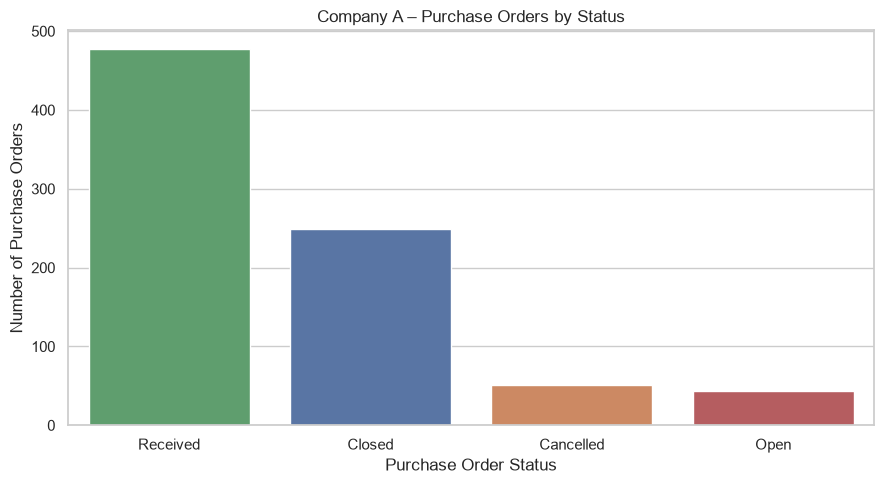

In [14]:
# Purchase orders by status
company_orders = company_a.drop_duplicates("po_number")

plt.figure(figsize=(9, 5))
sns.countplot(
    data=company_orders,
    x="status",
    order=company_orders["status"].value_counts().index,
    hue="status",
    legend=False
)

plt.title("Company A – Purchase Orders by Status")
plt.xlabel("Purchase Order Status")
plt.ylabel("Number of Purchase Orders")
plt.tight_layout()
plt.show()

In [15]:
# Inspect open purchase order lines
open_orders = company_a[
    company_a["status"] == "Open"
].copy()

display(open_orders.head(10))

,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount
317,PO-100125,CUST-A,VEND-01,2026-08-01,Open,ITM-0303,1,2.63,2.63
509,PO-100193,CUST-A,VEND-09,2026-06-12,Open,ITM-0201,10,4.20,42.00
510,PO-100193,CUST-A,VEND-09,2026-06-12,Open,ITM-0433,6,1.29,7.74
511,PO-100193,CUST-A,VEND-09,2026-06-12,Open,ITM-0721,10,38.85,388.50
512,PO-100193,CUST-A,VEND-09,2026-06-12,Open,ITM-1021,4,4.54,18.16
754,PO-100272,CUST-A,VEND-12,2026-09-01,Open,ITM-0612,2,4.14,8.28
953,PO-100347,CUST-A,VEND-06,2026-07-16,Open,ITM-0201,6,4.03,24.18
954,PO-100347,CUST-A,VEND-06,2026-07-16,Open,ITM-0311,6,6.71,40.26
955,PO-100347,CUST-A,VEND-06,2026-07-16,Open,ITM-0408,6,4.86,29.16
956,PO-100347,CUST-A,VEND-06,2026-07-16,Open,ITM-1015,4,4.22,16.88


In [16]:
# Exclude cancelled purchase orders
company_a_active = company_a[
    company_a["status"].isin(["Received", "Closed", "Open"])
].copy()

display(company_a_active)

,po_number,customer_id,vendor_id,order_date,status,item_id,quantity_ordered,unit_price_paid,extended_amount
0,PO-100000,CUST-A,VEND-06,2024-04-01,Closed,ITM-0431,10,0.72,7.20
9,PO-100003,CUST-A,VEND-09,2024-06-28,Closed,ITM-0201,24,3.80,91.20
10,PO-100003,CUST-A,VEND-09,2024-06-28,Closed,ITM-0442,1,18.89,18.89
14,PO-100005,CUST-A,VEND-08,2024-04-18,Closed,ITM-0614,6,4.91,29.46
22,PO-100009,CUST-A,VEND-12,2024-05-29,Closed,ITM-0612,1,3.97,3.97
...,...,...,...,...,...,...,...,...,...
8419,PO-103167,CUST-A,VEND-01,2025-10-16,Closed,ITM-0611,50,3.06,153.00
8420,PO-103167,CUST-A,VEND-01,2025-10-16,Closed,ITM-1006,1,1.32,1.32
8425,PO-103169,CUST-A,VEND-01,2026-04-03,Received,ITM-0623,3,2.56,7.68
8426,PO-103169,CUST-A,VEND-01,2026-04-03,Received,ITM-0627,10,7.37,73.70


In [17]:
# Separate priced and unpriced purchase lines
company_a_priced = company_a_active[
    company_a_active["unit_price_paid"].notna()
].copy()

company_a_unpriced = company_a_active[
    company_a_active["unit_price_paid"].isna()
].copy()

print("Active purchase lines:", len(company_a_active))
print("Priced lines:", len(company_a_priced))
print("Unpriced lines:", len(company_a_unpriced))

Active purchase lines: 2186
Priced lines: 2178
Unpriced lines: 8


In [18]:
# Rank items by purchase frequency
top_items_frequency = (
    company_a_active.groupby("item_id")
    .agg(
        purchase_frequency=("po_number", "nunique"),
        total_quantity=("quantity_ordered", "sum"),
        average_unit_price=("unit_price_paid", "mean"),
        total_spend=("extended_amount", "sum")
    )
    .reset_index()
    .sort_values(
        ["purchase_frequency", "total_spend"],
        ascending=[False, False]
    )
)

top_20_items = top_items_frequency.head(20)

display(top_20_items)

,item_id,purchase_frequency,total_quantity,average_unit_price,total_spend
48,ITM-0433,120,903,1.17,"1,018.17"
66,ITM-0612,119,997,3.97,"3,885.78"
115,ITM-1015,96,799,4.20,"3,281.34"
13,ITM-0237,84,525,3.10,"1,615.93"
1,ITM-0201,81,801,4.10,"3,174.94"
44,ITM-0426,66,623,24.03,"14,505.37"
25,ITM-0306,63,440,0.94,405.96
49,ITM-0434,55,546,1.44,772.40
70,ITM-0621,54,480,3.95,"1,876.87"
101,ITM-0929,54,417,1.14,457.94


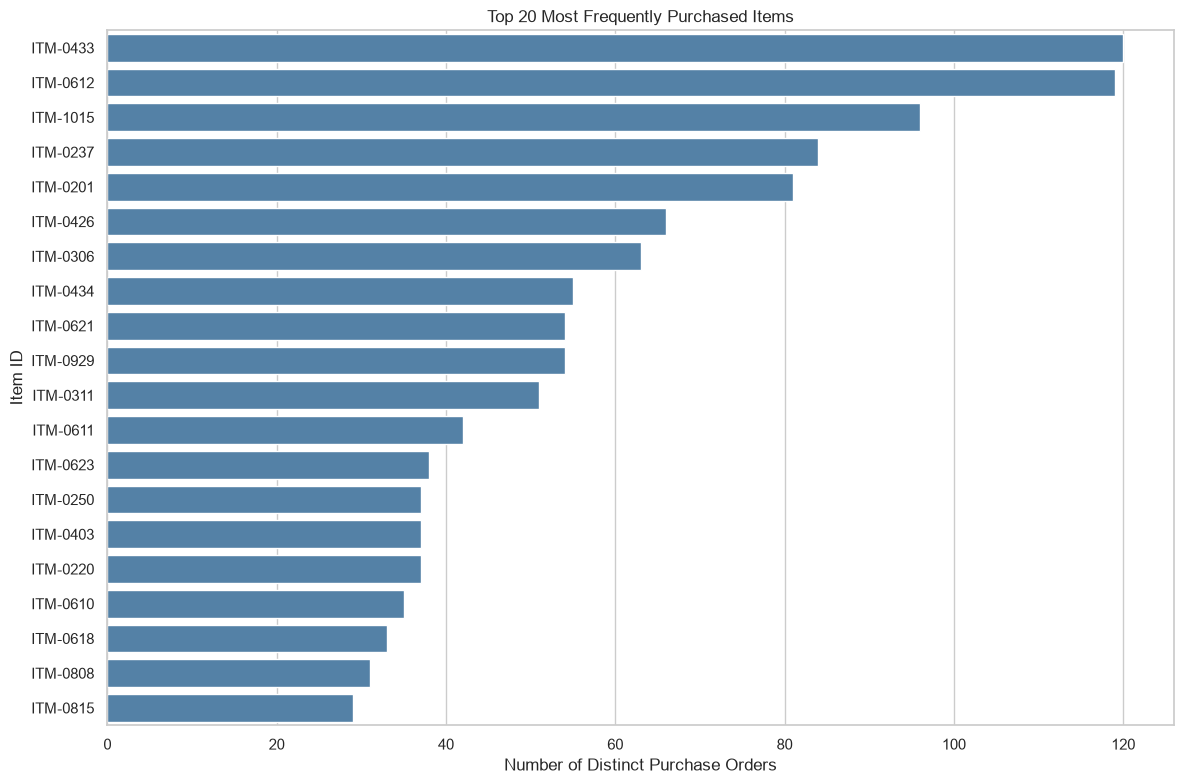

In [19]:
# Plot and save top 20 items by purchase frequency
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_items,
    x="purchase_frequency",
    y="item_id",
    color="steelblue"
)

plt.title("Top 20 Most Frequently Purchased Items")
plt.xlabel("Number of Distinct Purchase Orders")
plt.ylabel("Item ID")
plt.tight_layout()

plt.savefig(CHARTS_DIR / "top_20_items_by_frequency.png", dpi=300)
plt.show()

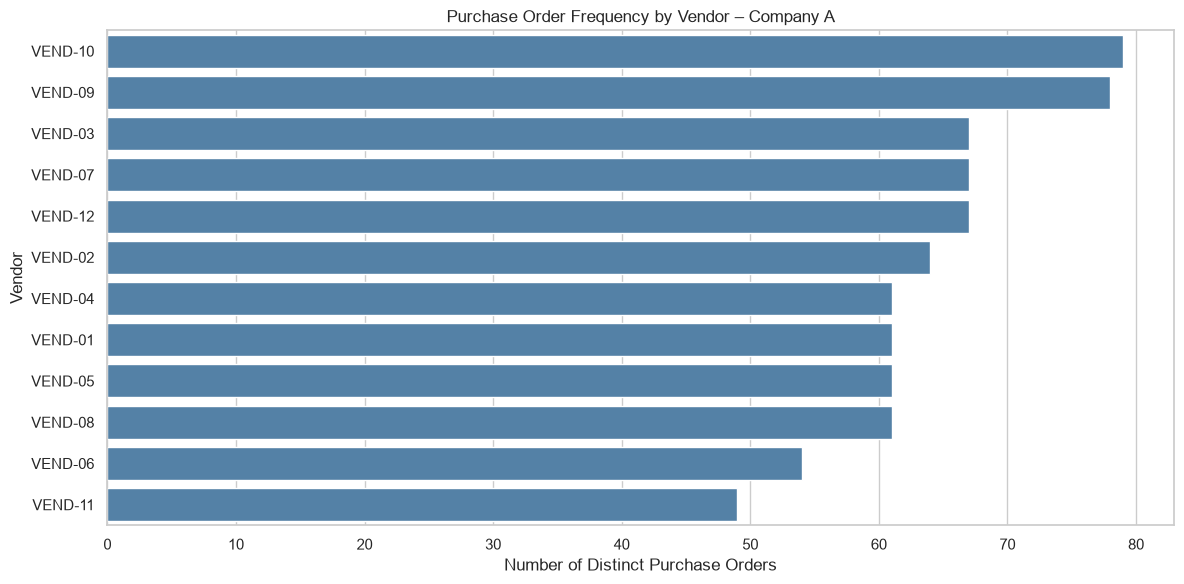

In [20]:
# Rank and visualize vendors by purchase frequency
vendor_frequency = (
    company_a_active.groupby("vendor_id")
    .agg(
        purchase_frequency=("po_number", "nunique")
    )
    .reset_index()
    .sort_values("purchase_frequency", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=vendor_frequency,
    x="purchase_frequency",
    y="vendor_id",
    color="steelblue"
)

plt.title("Purchase Order Frequency by Vendor – Company A")
plt.xlabel("Number of Distinct Purchase Orders")
plt.ylabel("Vendor")
plt.tight_layout()

plt.savefig(CHARTS_DIR / "vendor_purchase_frequency.png", dpi=300, bbox_inches="tight")
plt.show()

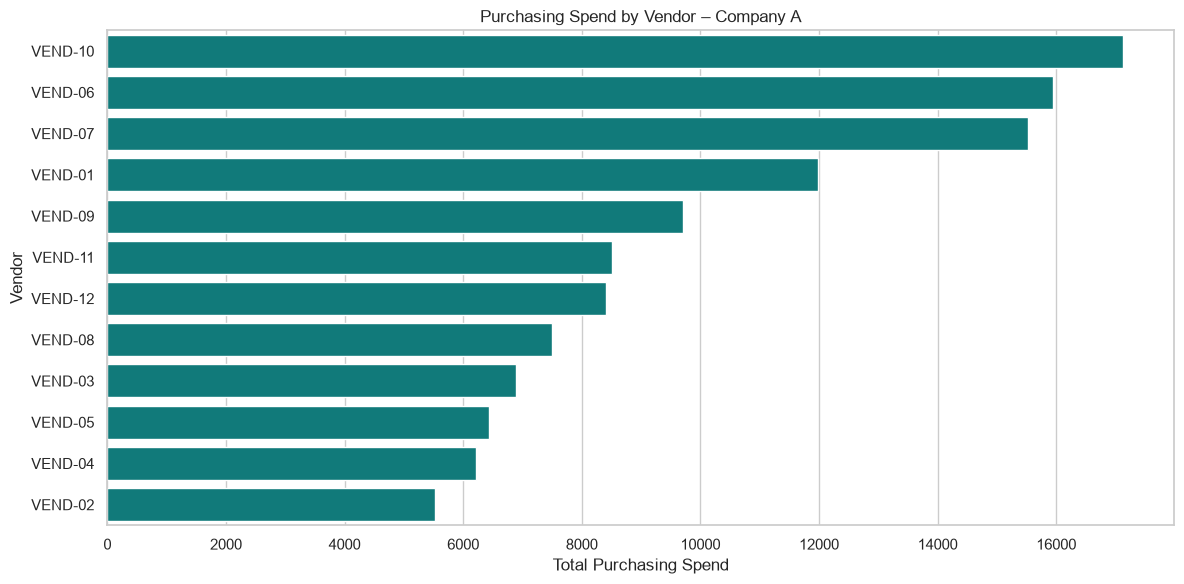

In [21]:
# Rank and visualize vendors by purchasing spend
vendor_spend = (
    company_a_priced.groupby("vendor_id")
    .agg(
        total_spend=("extended_amount", "sum"),
        purchase_orders=("po_number", "nunique"),
        purchase_lines=("po_number", "count")
    )
    .reset_index()
    .sort_values("total_spend", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=vendor_spend,
    x="total_spend",
    y="vendor_id",
    color="darkcyan"
)

plt.title("Purchasing Spend by Vendor – Company A")
plt.xlabel("Total Purchasing Spend")
plt.ylabel("Vendor")
plt.tight_layout()

plt.savefig(CHARTS_DIR / "vendor_purchasing_spend.png", dpi=300, bbox_inches="tight")
plt.show()

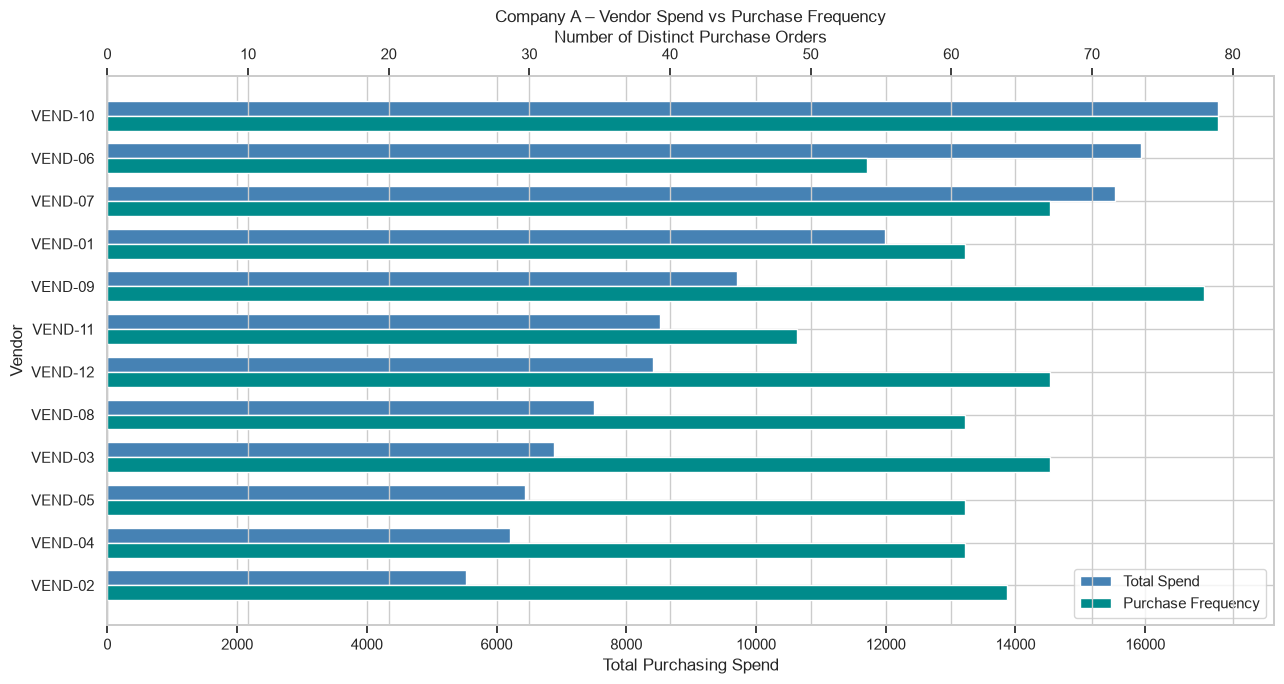

In [22]:

# Compare vendor purchasing frequency and total expenditure
vendor_comparison = (
    company_a_active.groupby("vendor_id")
    .agg(purchase_frequency=("po_number", "nunique"),
         total_spend=("extended_amount", "sum"))
    .reset_index()
    .sort_values("total_spend", ascending=False)
)

# Visualize and save vendor spend vs purchase frequency
fig, ax1 = plt.subplots(figsize=(13, 7))
y = np.arange(len(vendor_comparison))
height = 0.35

ax1.barh(y - height / 2, vendor_comparison["total_spend"], height,
         color="steelblue", label="Total Spend")
ax1.set(yticks=y, yticklabels=vendor_comparison["vendor_id"],
        xlabel="Total Purchasing Spend", ylabel="Vendor")
ax1.invert_yaxis()

ax2 = ax1.twiny()
ax2.barh(y + height / 2, vendor_comparison["purchase_frequency"], height,
         color="darkcyan", label="Purchase Frequency")
ax2.set_xlabel("Number of Distinct Purchase Orders")

ax1.set_title("Company A – Vendor Spend vs Purchase Frequency")
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="lower right")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "vendor_spend_vs_frequency.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# Compare item purchasing frequency and expenditure, retaining the top 20 by spend
item_comparison = (
    company_a_active.groupby("item_id")
    .agg(
        purchase_frequency=("po_number", "nunique"),
        total_spend=("extended_amount", "sum")
    )
    .reset_index()
)

# Exclude missing amounts from spend calculation
item_spend = (
    company_a_active.dropna(subset=["extended_amount"])
    .groupby("item_id")["extended_amount"]
    .sum()
    .reset_index(name="total_spend")
)

item_comparison = (
    item_comparison.drop(columns="total_spend")
    .merge(item_spend, on="item_id", how="left")
    .sort_values("total_spend", ascending=False)
    .head(20)
)

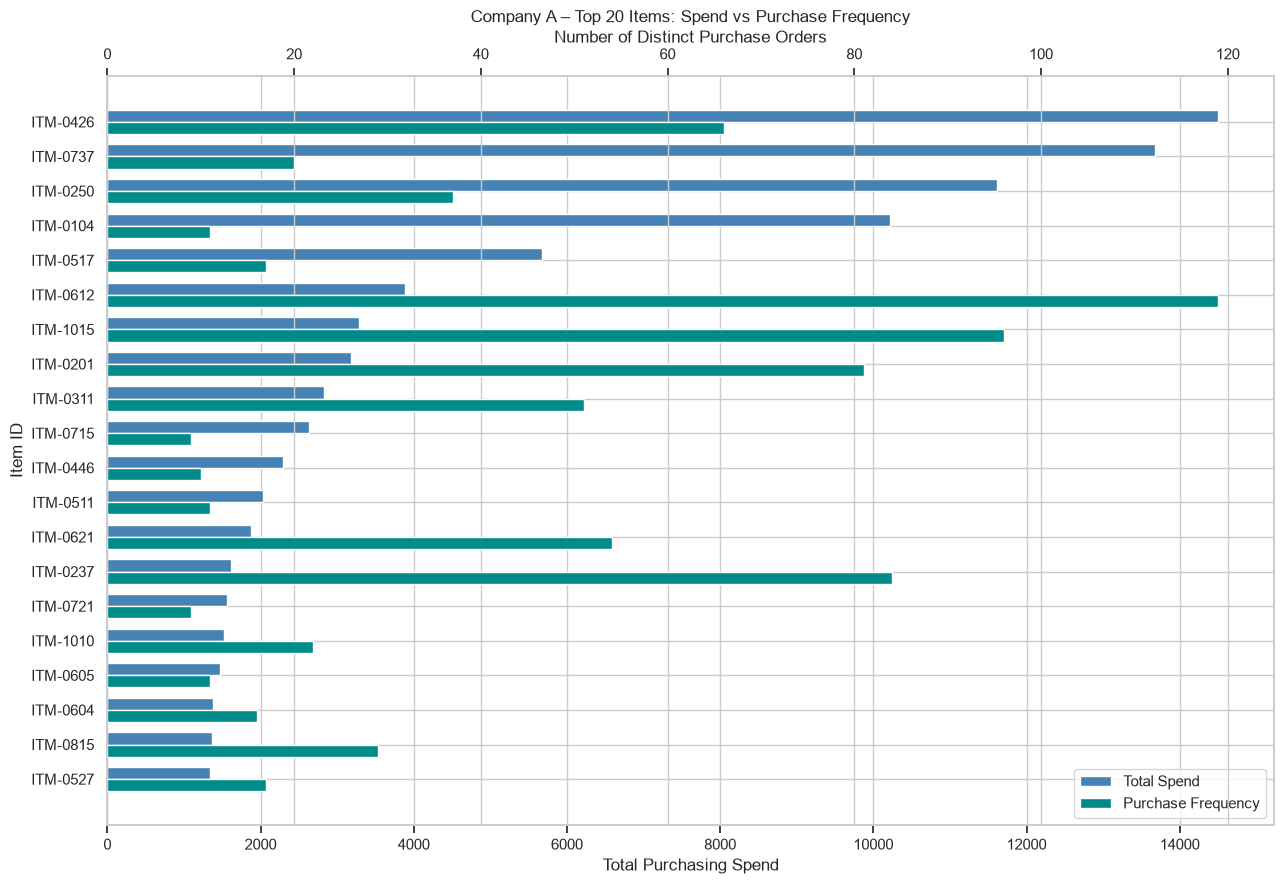

In [24]:

# Compare purchasing expenditure and frequency for the top 20 items
item_comparison = (
    company_a_active.groupby("item_id")
    .agg(purchase_frequency=("po_number", "nunique"),
         total_spend=("extended_amount", lambda x: x.sum(min_count=1)))
    .reset_index()
    .sort_values("total_spend", ascending=False)
    .head(20)
)

# Visualize and save item spend vs purchase frequency
fig, ax1 = plt.subplots(figsize=(13, 9))
y = np.arange(len(item_comparison))
height = 0.35

ax1.barh(y - height / 2, item_comparison["total_spend"], height,
         color="steelblue", label="Total Spend")
ax1.set(yticks=y, yticklabels=item_comparison["item_id"],
        xlabel="Total Purchasing Spend", ylabel="Item ID")
ax1.invert_yaxis()

ax2 = ax1.twiny()
ax2.barh(y + height / 2, item_comparison["purchase_frequency"], height,
         color="darkcyan", label="Purchase Frequency")
ax2.set_xlabel("Number of Distinct Purchase Orders")

ax1.set_title("Company A – Top 20 Items: Spend vs Purchase Frequency")
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="lower right")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "item_spend_frequency_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [25]:
# Aggregate Company A purchasing activity and expenditure by month
company_a_active["year_month"] = company_a_active["order_date"].dt.to_period("M")

monthly_trends = (
    company_a_active.groupby("year_month")
    .agg(purchase_orders=("po_number", "nunique"),
         total_quantity=("quantity_ordered", "sum"),
         total_spend=("extended_amount", lambda x: x.sum(min_count=1)),
         average_unit_price=("unit_price_paid", "mean"))
    .reset_index()
    .sort_values("year_month")
)

monthly_trends["year_month"] = monthly_trends["year_month"].astype(str)

display(monthly_trends.head(12))


,year_month,purchase_orders,total_quantity,total_spend,average_unit_price
0,2024-01,27,608,"4,203.61",6.35
1,2024-02,23,516,"4,364.40",8.51
2,2024-03,15,225,"1,208.98",6.56
3,2024-04,22,540,"4,191.27",6.57
4,2024-05,31,1034,"3,645.06",4.53
5,2024-06,31,727,"4,758.12",6.51
6,2024-07,21,431,"2,161.24",8.40
7,2024-08,28,544,"2,742.59",5.33
8,2024-09,21,440,"2,230.30",7.09
9,2024-10,13,208,996.38,4.85


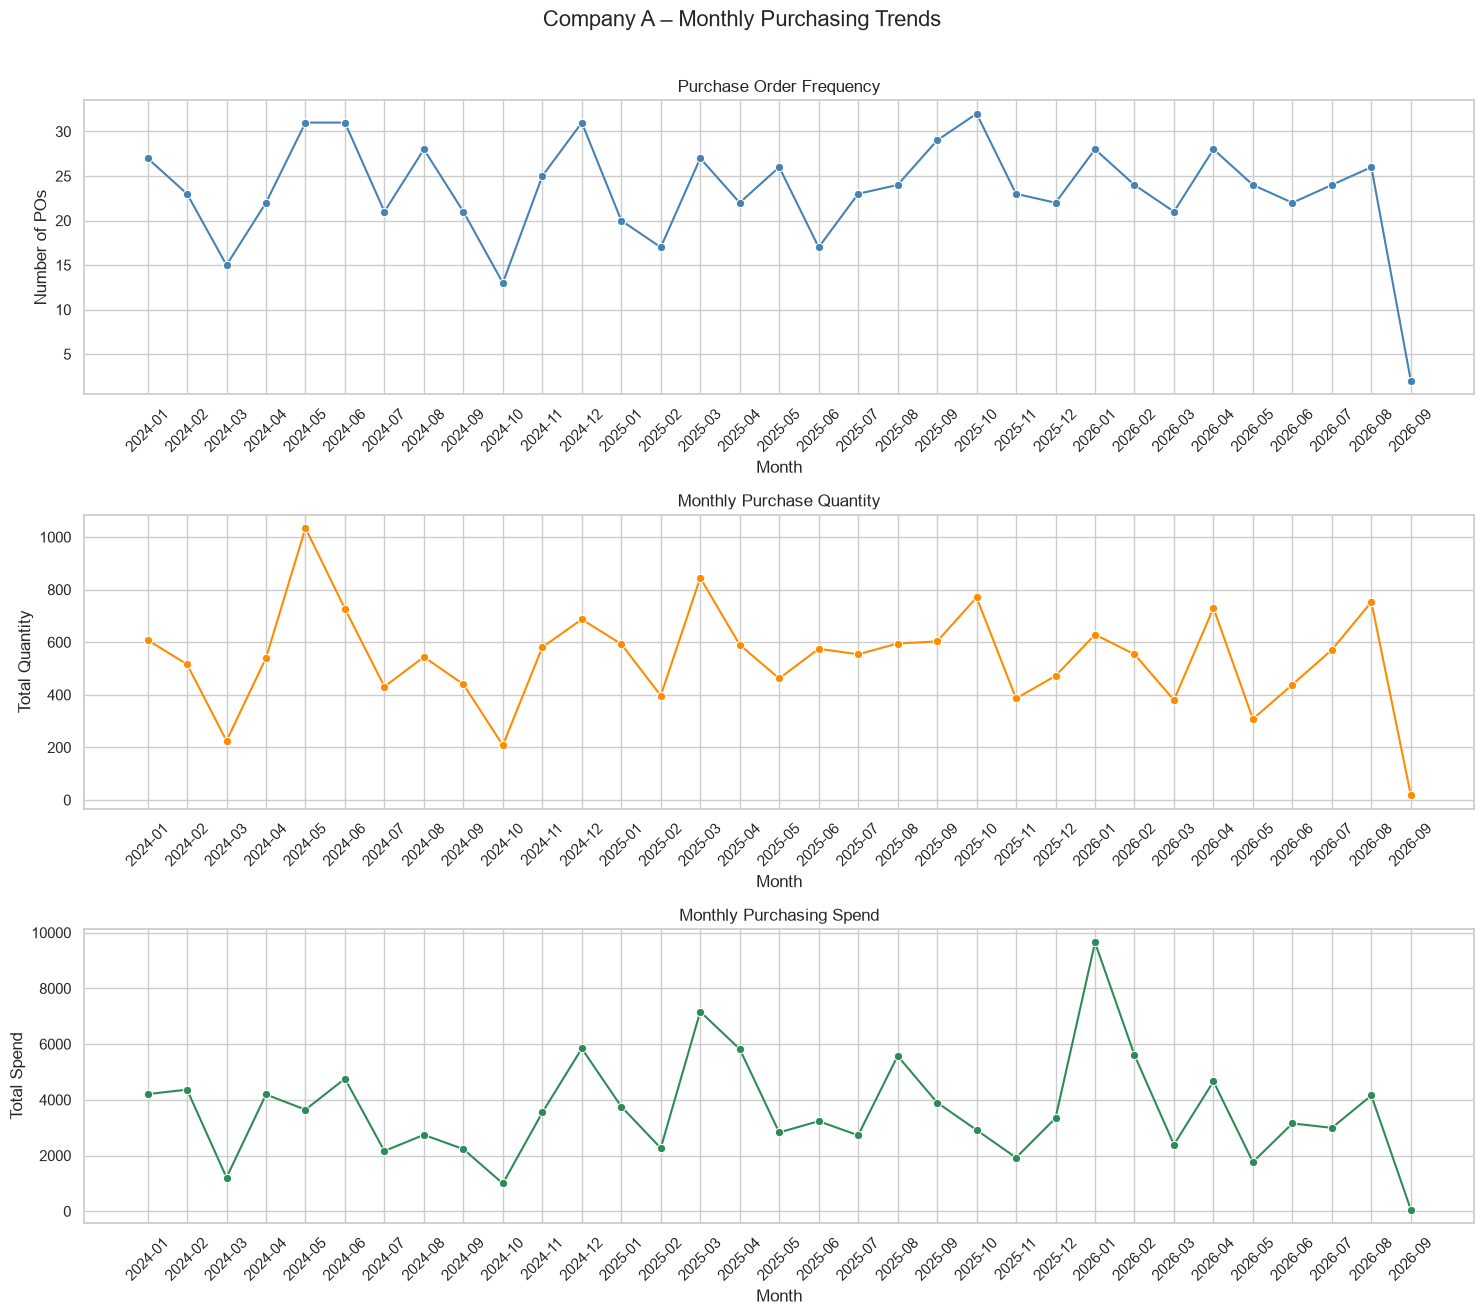

In [26]:
# Analyse and visualize Company A's monthly purchasing trends
monthly_trends = (
    company_a_active
    .assign(year_month=company_a_active["order_date"].dt.to_period("M"))
    .groupby("year_month")
    .agg(purchase_frequency=("po_number", "nunique"),
         total_quantity=("quantity_ordered", "sum"),
         total_spend=("extended_amount", lambda x: x.sum(min_count=1)))
    .reset_index()
)
monthly_trends["year_month"] = monthly_trends["year_month"].astype(str)

# Create and save three monthly trend charts
fig, axes = plt.subplots(3, 1, figsize=(15, 13))
metrics = [
    ("purchase_frequency", "Purchase Order Frequency", "Number of POs", "steelblue"),
    ("total_quantity", "Monthly Purchase Quantity", "Total Quantity", "darkorange"),
    ("total_spend", "Monthly Purchasing Spend", "Total Spend", "seagreen")
]

for ax, (column, title, ylabel, color) in zip(axes, metrics):
    sns.lineplot(data=monthly_trends, x="year_month", y=column,
                 marker="o", color=color, ax=ax)
    ax.set(title=title, xlabel="Month", ylabel=ylabel)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Company A – Monthly Purchasing Trends", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "monthly_purchasing_trends.png", dpi=300, bbox_inches="tight")
plt.show()


In [27]:
# Analyse monthly average and median unit prices and transaction volumes
monthly_prices = (
    company_a_active.dropna(subset=["unit_price_paid"])
    .assign(year_month=lambda x: x["order_date"].dt.to_period("M"))
    .groupby("year_month")
    .agg(average_unit_price=("unit_price_paid", "mean"),
         median_unit_price=("unit_price_paid", "median"),
         transactions=("unit_price_paid", "count"))
    .reset_index()
    .sort_values("year_month")
)

monthly_prices["year_month"] = monthly_prices["year_month"].astype(str)
display(monthly_prices.head(12))

,year_month,average_unit_price,median_unit_price,transactions
0,2024-01,6.35,2.52,62
1,2024-02,8.51,3.79,70
2,2024-03,6.56,2.93,39
3,2024-04,6.57,3.29,57
4,2024-05,4.53,2.89,107
5,2024-06,6.51,3.15,85
6,2024-07,8.40,3.11,56
7,2024-08,5.33,2.50,79
8,2024-09,7.09,3.19,57
9,2024-10,4.85,3.76,34


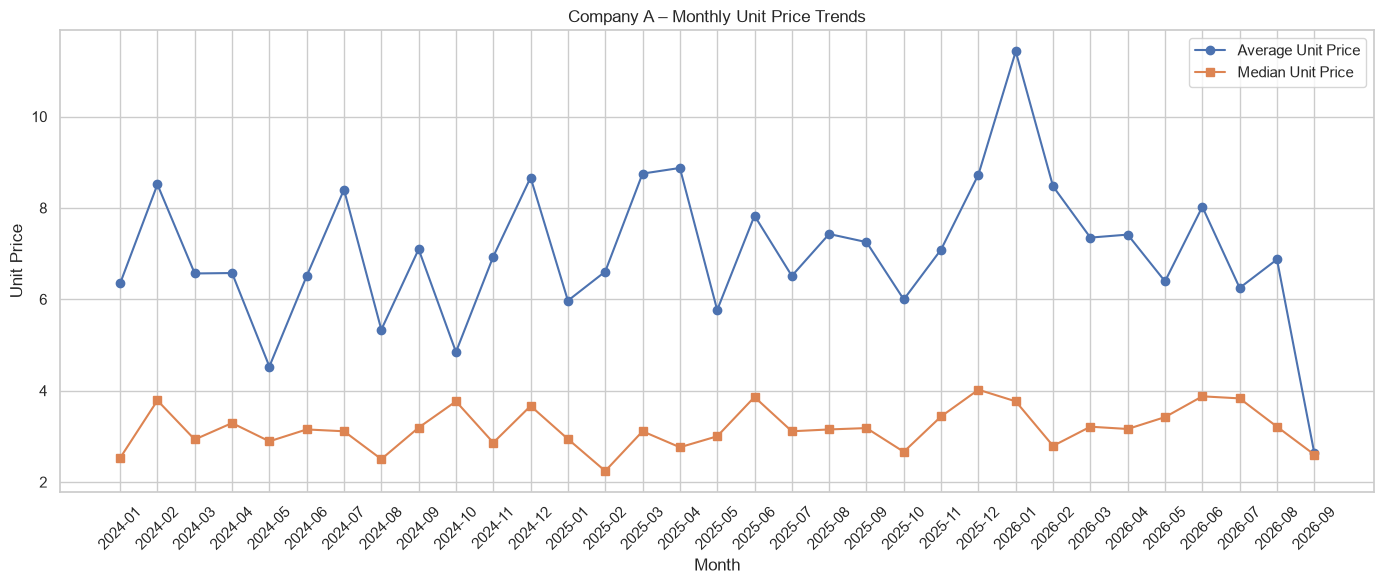

In [28]:
# Visualize monthly average and median unit price trends
plt.figure(figsize=(14, 6))
plt.plot(monthly_prices["year_month"], monthly_prices["average_unit_price"],
         marker="o", label="Average Unit Price")
plt.plot(monthly_prices["year_month"], monthly_prices["median_unit_price"],
         marker="s", label="Median Unit Price")

plt.title("Company A – Monthly Unit Price Trends")
plt.xlabel("Month")
plt.ylabel("Unit Price")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "monthly_unit_price_trends.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
# Rank months by average unit price from highest to lowest
display(monthly_prices.sort_values("average_unit_price", ascending=False))

,year_month,average_unit_price,median_unit_price,transactions
24,2026-01,11.42,3.76,68
15,2025-04,8.87,2.76,75
14,2025-03,8.75,3.11,88
23,2025-12,8.73,4.02,72
11,2024-12,8.66,3.67,82
1,2024-02,8.51,3.79,70
25,2026-02,8.47,2.79,69
6,2024-07,8.40,3.11,56
29,2026-06,8.02,3.88,70
17,2025-06,7.83,3.86,53


In [30]:
# Analyse January 2026 purchasing frequency, quantities and average item prices
jan_2026 = company_a_active[
    (company_a_active["order_date"].dt.year == 2026) &
    (company_a_active["order_date"].dt.month == 1)
].copy()

jan_2026_items = (
    jan_2026.groupby("item_id")
    .agg(purchase_frequency=("po_number", "nunique"),
         total_quantity=("quantity_ordered", "sum"),
         average_unit_price=("unit_price_paid", "mean"))
    .reset_index()
    .sort_values("average_unit_price", ascending=False)
)

display(jan_2026_items)

,item_id,purchase_frequency,total_quantity,average_unit_price
30,ITM-0737,1,10,74.22
28,ITM-0715,2,8,70.57
6,ITM-0250,2,12,60.75
0,ITM-0104,2,74,58.70
18,ITM-0517,2,28,39.00
29,ITM-0721,1,1,31.64
15,ITM-0426,1,24,24.16
19,ITM-0605,1,6,16.46
40,ITM-1010,2,11,8.88
32,ITM-0815,1,24,7.79


In [31]:
# Identify the top 10 most frequently purchased items by distinct purchase orders
top_10_items = (
    company_a_active.groupby("item_id")["po_number"]
    .nunique()
    .nlargest(10)
    .index
)

In [32]:
# Analyse monthly unit prices, purchase frequency and quantities for the top 10 items
item_monthly_prices = (
    company_a_active[company_a_active["item_id"].isin(top_10_items)]
    .dropna(subset=["unit_price_paid"])
    .assign(year_month=lambda x: x["order_date"].dt.to_period("M"))
    .groupby(["item_id", "year_month"])
    .agg(average_unit_price=("unit_price_paid", "mean"),
         purchase_frequency=("po_number", "nunique"),
         total_quantity=("quantity_ordered", "sum"))
    .reset_index()
    .sort_values(["item_id", "year_month"])
)

item_monthly_prices["year_month"] = item_monthly_prices["year_month"].astype(str)
display(item_monthly_prices)

,item_id,year_month,average_unit_price,purchase_frequency,total_quantity
0,ITM-0201,2024-01,4.06,2,12
1,ITM-0201,2024-02,4.05,4,42
2,ITM-0201,2024-03,4.15,2,5
3,ITM-0201,2024-04,3.93,2,10
4,ITM-0201,2024-05,3.64,2,52
...,...,...,...,...,...
287,ITM-1015,2026-02,4.38,3,22
288,ITM-1015,2026-03,4.40,2,16
289,ITM-1015,2026-06,4.34,2,16
290,ITM-1015,2026-07,4.25,8,48


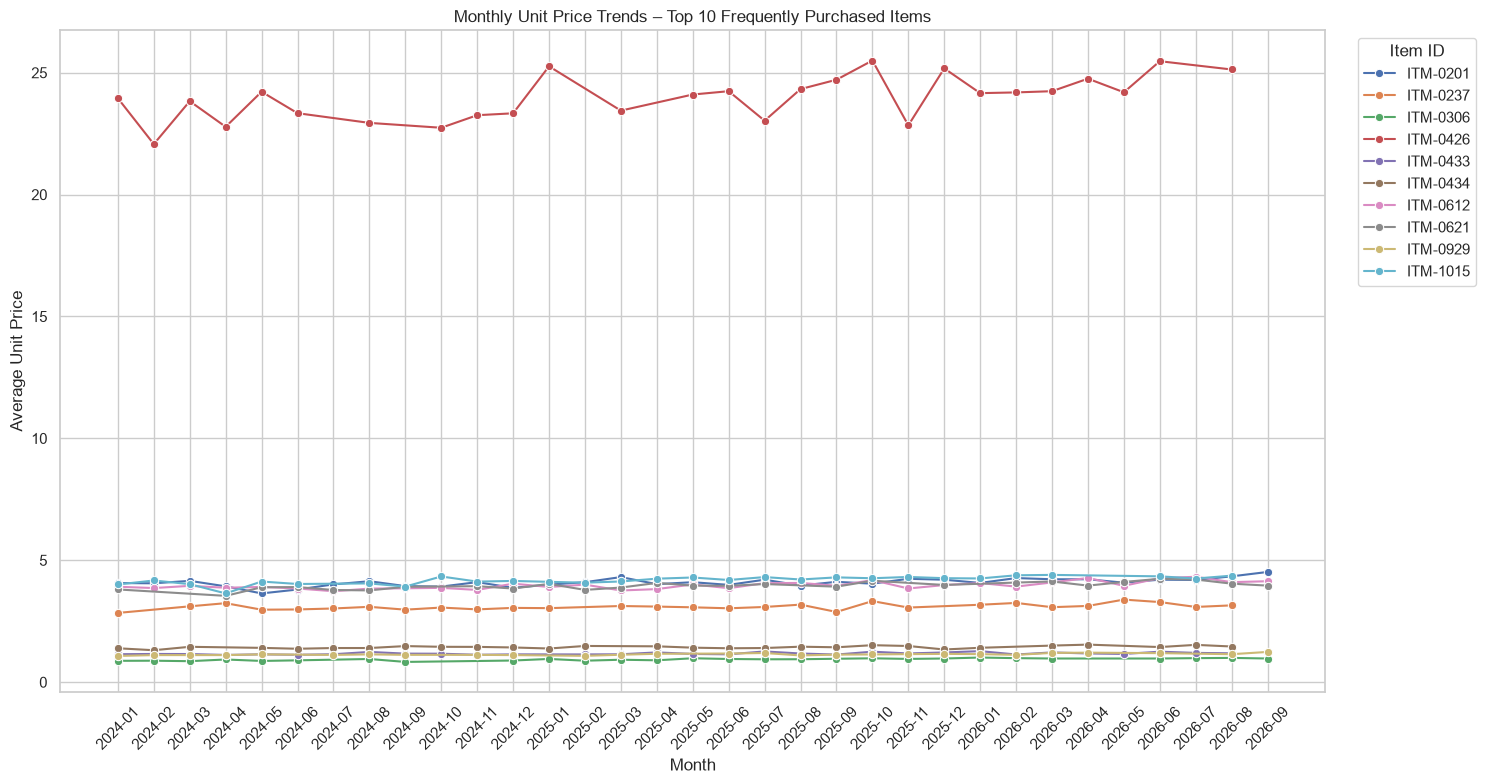

In [33]:
# Visualize monthly unit price trends for the top 10 frequently purchased items
plt.figure(figsize=(15, 8))
sns.lineplot(data=item_monthly_prices, x="year_month", y="average_unit_price",
             hue="item_id", marker="o")

plt.title("Monthly Unit Price Trends – Top 10 Frequently Purchased Items")
plt.xlabel("Month")
plt.ylabel("Average Unit Price")
plt.xticks(rotation=45)
plt.legend(title="Item ID", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top_10_items_monthly_price_trends.png", dpi=300, bbox_inches="tight")
plt.show()

In [34]:
# Examine the priced purchasing history of item ITM-0426
item_0426 = (
    company_a_active[
        (company_a_active["item_id"] == "ITM-0426") &
        company_a_active["unit_price_paid"].notna()
    ]
    .sort_values("order_date")
)

display(item_0426[["po_number", "order_date", "vendor_id",
                   "quantity_ordered", "unit_price_paid", "extended_amount"]])

,po_number,order_date,vendor_id,quantity_ordered,unit_price_paid,extended_amount
5631,PO-102125,2024-01-12,VEND-01,4,23.95,95.80
7577,PO-102859,2024-02-23,VEND-12,50,20.92,"1,046.00"
94,PO-100035,2024-02-25,VEND-01,10,23.22,232.20
5837,PO-102204,2024-03-05,VEND-12,4,24.08,96.32
5803,PO-102191,2024-03-26,VEND-01,2,23.58,47.16
7834,PO-102961,2024-04-19,VEND-01,6,22.92,137.52
3954,PO-101503,2024-04-21,VEND-01,10,22.64,226.40
5751,PO-102169,2024-05-02,VEND-01,12,24.25,291.00
6372,PO-102416,2024-05-04,VEND-12,4,23.10,92.40
356,PO-100138,2024-05-23,VEND-12,10,24.80,248.00


In [35]:
print(item_0426["unit_price_paid"].describe())

count   67.00
mean    24.03
std      1.15
min     20.19
25%     23.23
50%     23.90
75%     24.88
max     26.10
Name: unit_price_paid, dtype: float64


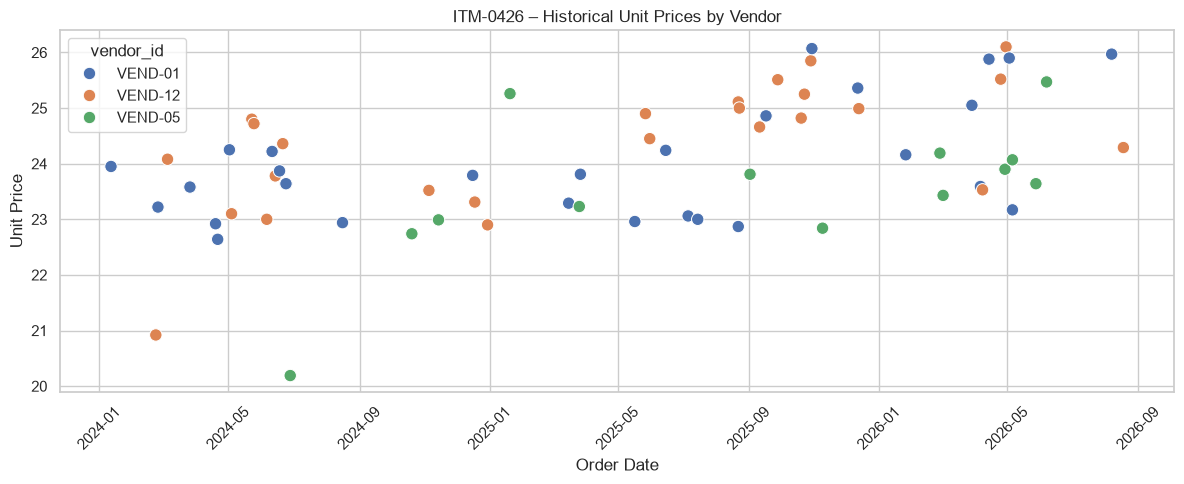

In [36]:
# Visualize historical unit prices of ITM-0426 by vendor
plt.figure(figsize=(12, 5))
sns.scatterplot(data=item_0426, x="order_date", y="unit_price_paid",
                hue="vendor_id", s=80)

plt.title("ITM-0426 – Historical Unit Prices by Vendor")
plt.xlabel("Order Date")
plt.ylabel("Unit Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "item_0426_historical_prices_by_vendor.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
# Compare historical purchasing prices for ITM-0426 across vendors
item_0426_vendor = (
    item_0426.groupby("vendor_id")
    .agg(purchase_lines=("po_number", "count"),
         average_price=("unit_price_paid", "mean"),
         median_price=("unit_price_paid", "median"),
         minimum_price=("unit_price_paid", "min"),
         maximum_price=("unit_price_paid", "max"))
    .reset_index()
    .sort_values("average_price")
)

display(item_0426_vendor)

,vendor_id,purchase_lines,average_price,median_price,minimum_price,maximum_price
1,VEND-05,13,23.52,23.64,20.19,25.47
0,VEND-01,29,24.00,23.79,22.64,26.07
2,VEND-12,25,24.34,24.66,20.92,26.10


In [38]:
# Analyse monthly average and median prices and transaction volumes for ITM-0426
item_0426_monthly = (
    item_0426.assign(month=item_0426["order_date"].dt.month)
    .groupby("month")
    .agg(average_price=("unit_price_paid", "mean"),
         median_price=("unit_price_paid", "median"),
         transactions=("po_number", "count"))
    .reset_index()
    .sort_values("month")
)

display(item_0426_monthly)

,month,average_price,median_price,transactions
0,1,24.46,24.16,3
1,2,22.78,23.22,3
2,3,23.78,23.58,7
3,4,24.26,23.74,8
4,5,24.18,24.25,11
5,6,23.64,23.83,10
6,7,23.03,23.03,2
7,8,24.36,24.64,6
8,9,24.71,24.76,4
9,10,24.95,25.25,5


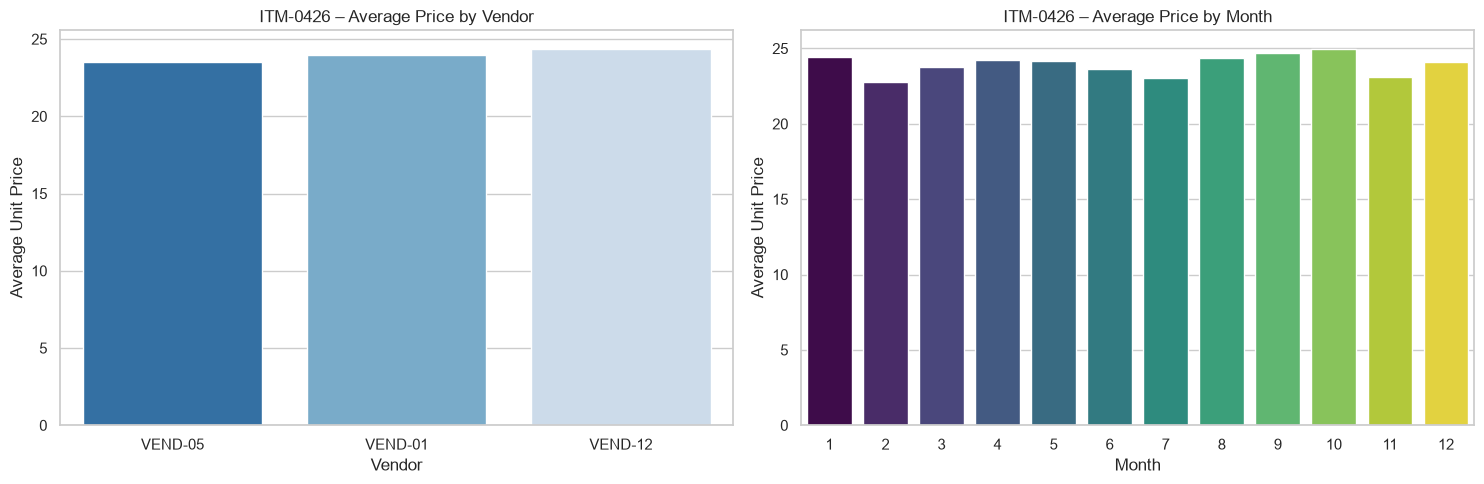

In [39]:
# Compare ITM-0426 average unit prices by vendor and month
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=item_0426_vendor, x="vendor_id", y="average_price",
            hue="vendor_id", palette="Blues_r", legend=False, ax=axes[0])
axes[0].set(title="ITM-0426 – Average Price by Vendor",
            xlabel="Vendor", ylabel="Average Unit Price")

sns.barplot(data=item_0426_monthly, x="month", y="average_price",
            hue="month", palette="viridis", legend=False, ax=axes[1])
axes[1].set(title="ITM-0426 – Average Price by Month",
            xlabel="Month", ylabel="Average Unit Price")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "item_0426_vendor_monthly_price_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [40]:
# Compare vendor purchasing prices and order volumes for the top 10 most frequently purchased items 

top_10_vendor_prices = (
    company_a_active[company_a_active["item_id"].isin(top_10_items)]
    .dropna(subset=["unit_price_paid"])
    .groupby(["item_id", "vendor_id"])
    .agg(purchase_lines=("po_number", "count"),
         purchase_orders=("po_number", "nunique"),
         average_price=("unit_price_paid", "mean"),
         median_price=("unit_price_paid", "median"))
    .reset_index()
    .sort_values(["item_id", "average_price"])
)

display(top_10_vendor_prices)

,item_id,vendor_id,purchase_lines,purchase_orders,average_price,median_price
1,ITM-0201,VEND-06,13,13,3.99,3.97
0,ITM-0201,VEND-02,14,13,4.00,4.08
3,ITM-0201,VEND-09,28,28,4.10,4.12
2,ITM-0201,VEND-08,27,27,4.20,4.19
5,ITM-0237,VEND-04,39,39,3.02,3.04
4,ITM-0237,VEND-02,46,45,3.16,3.17
9,ITM-0306,VEND-08,19,18,0.92,0.94
6,ITM-0306,VEND-03,21,18,0.93,0.94
8,ITM-0306,VEND-07,16,16,0.95,0.96
7,ITM-0306,VEND-04,11,11,0.96,0.96


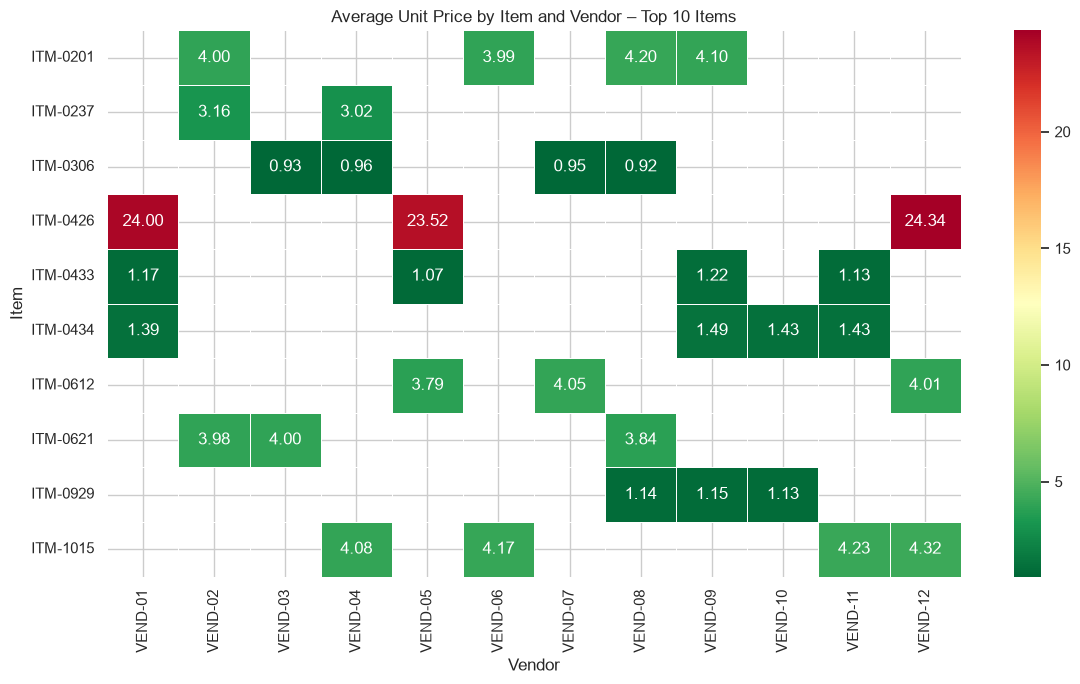

In [41]:
# Visualize average unit prices by item and vendor for the top 10 most frequently purchased items 
price_pivot = top_10_vendor_prices.pivot(
    index="item_id", columns="vendor_id", values="average_price"
)

plt.figure(figsize=(12, 7))
sns.heatmap(price_pivot, annot=True, fmt=".2f", cmap="RdYlGn_r",
            linewidths=0.5)

plt.title("Average Unit Price by Item and Vendor – Top 10 Items")
plt.xlabel("Vendor")
plt.ylabel("Item")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top10_item_vendor_price_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
# Identify the cheapest vendor for each of the top 10 frequently purchased items
cheapest_vendor = (
    top_10_vendor_prices.sort_values("average_price")
    .groupby("item_id")
    .first()
    .reset_index()
)

display(cheapest_vendor)

,item_id,vendor_id,purchase_lines,purchase_orders,average_price,median_price
0,ITM-0201,VEND-06,13,13,3.99,3.97
1,ITM-0237,VEND-04,39,39,3.02,3.04
2,ITM-0306,VEND-08,19,18,0.92,0.94
3,ITM-0426,VEND-05,13,13,23.52,23.64
4,ITM-0433,VEND-05,22,22,1.07,1.08
5,ITM-0434,VEND-01,13,12,1.39,1.39
6,ITM-0612,VEND-05,29,28,3.79,3.75
7,ITM-0621,VEND-08,18,18,3.84,3.88
8,ITM-0929,VEND-10,24,24,1.13,1.12
9,ITM-1015,VEND-04,21,19,4.08,4.09


In [43]:
# Analyse monthly average and median prices for the top 10 frequently purchased items
top_10_monthly_prices = (
    company_a_active[company_a_active["item_id"].isin(top_10_items)]
    .dropna(subset=["unit_price_paid"])
    .assign(month=lambda x: x["order_date"].dt.month)
    .groupby(["item_id", "month"])
    .agg(average_price=("unit_price_paid", "mean"),
         median_price=("unit_price_paid", "median"),
         transactions=("po_number", "nunique"))
    .reset_index()
    .sort_values(["item_id", "month"])
)

display(top_10_monthly_prices)

,item_id,month,average_price,median_price,transactions
0,ITM-0201,1,4.06,4.04,7
1,ITM-0201,2,4.12,4.12,9
2,ITM-0201,3,4.21,4.22,4
3,ITM-0201,4,4.06,4.06,6
4,ITM-0201,5,3.94,4.05,6
...,...,...,...,...,...
115,ITM-1015,8,4.29,4.30,10
116,ITM-1015,9,4.15,4.15,10
117,ITM-1015,10,4.28,4.25,6
118,ITM-1015,11,4.25,4.20,6


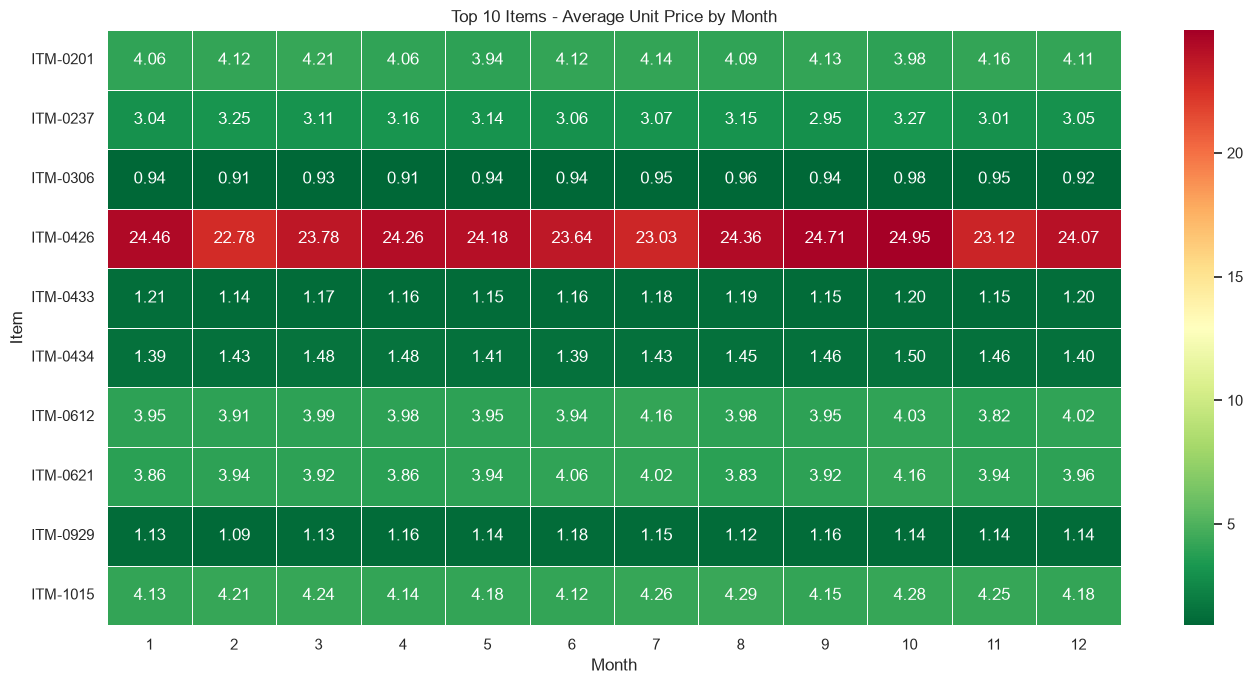

In [44]:
# Visualize monthly average unit prices for the top 10 frequently purchased items
price_month_pivot = top_10_monthly_prices.pivot(
    index="item_id", columns="month", values="average_price"
)

plt.figure(figsize=(14, 7))
sns.heatmap(price_month_pivot, annot=True, fmt=".2f",
            cmap="RdYlGn_r", linewidths=0.5)

plt.title("Top 10 Items - Average Unit Price by Month")
plt.xlabel("Month")
plt.ylabel("Item")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top10_items_monthly_price_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

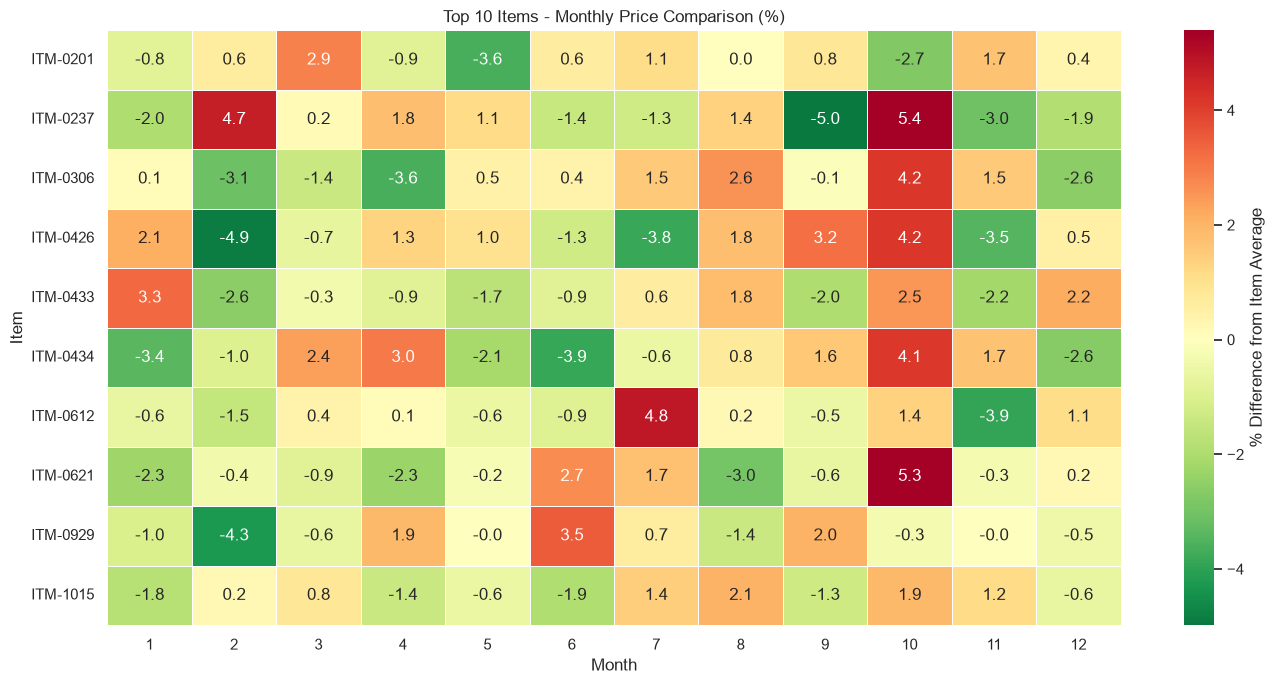

In [45]:
# Visualise monthly price differences relative to each item's average price
price_month_pivot = top_10_monthly_prices.pivot(index="item_id", columns="month", values="average_price")
item_avg_price = price_month_pivot.mean(axis=1)
price_month_pct = price_month_pivot.sub(item_avg_price, axis=0).div(item_avg_price, axis=0) * 100
plt.figure(figsize=(14, 7))
sns.heatmap(price_month_pct, annot=True, fmt=".1f", cmap="RdYlGn_r", center=0, linewidths=0.5, cbar_kws={"label": "% Difference from Item Average"})
plt.title("Top 10 Items - Monthly Price Comparison (%)")
plt.xlabel("Month")
plt.ylabel("Item")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top10_items_monthly_price_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

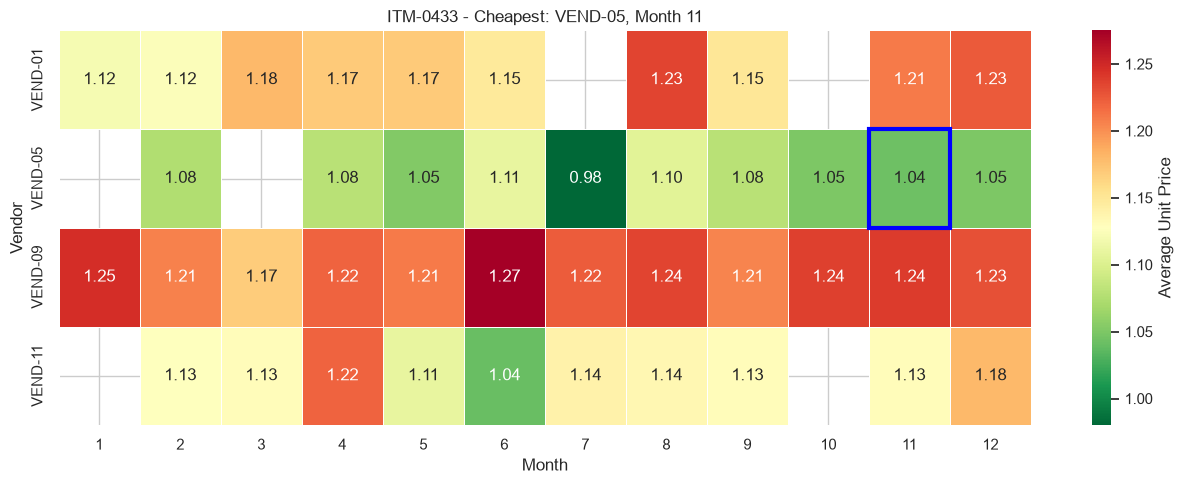

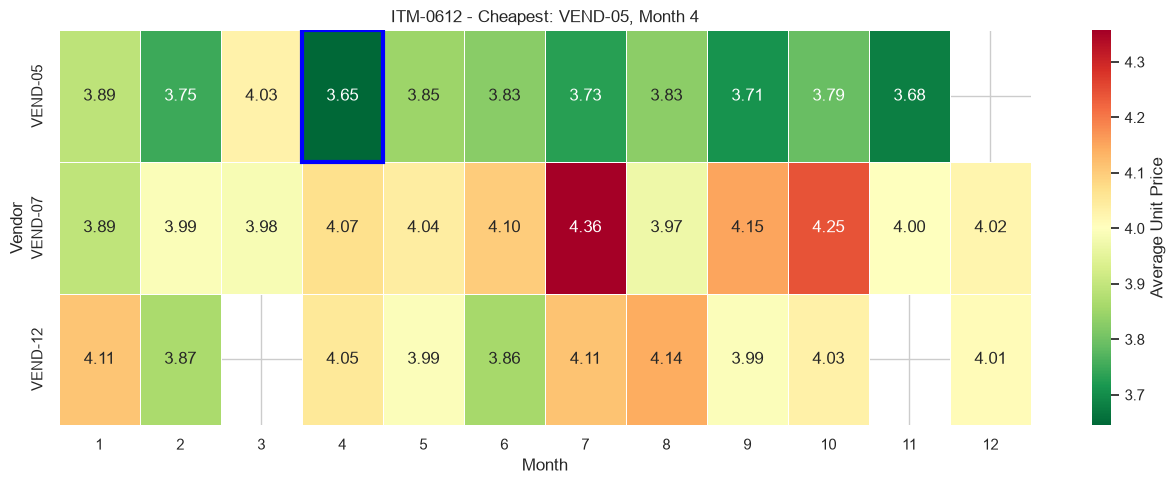

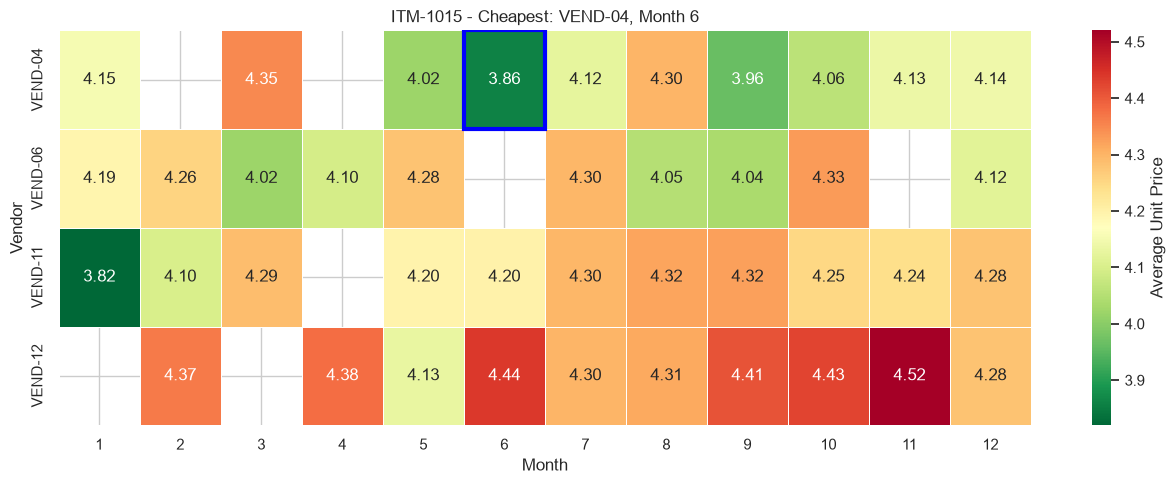

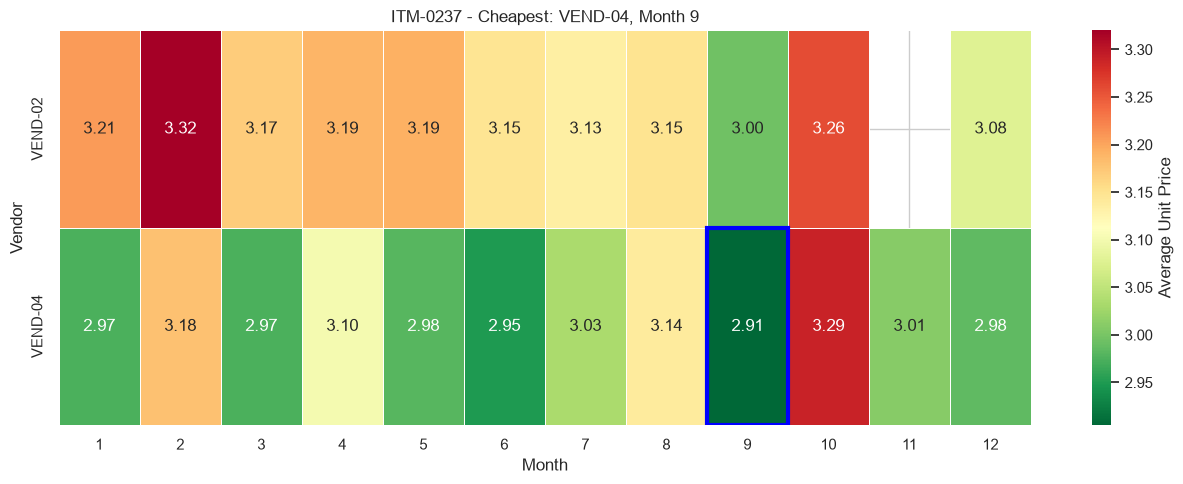

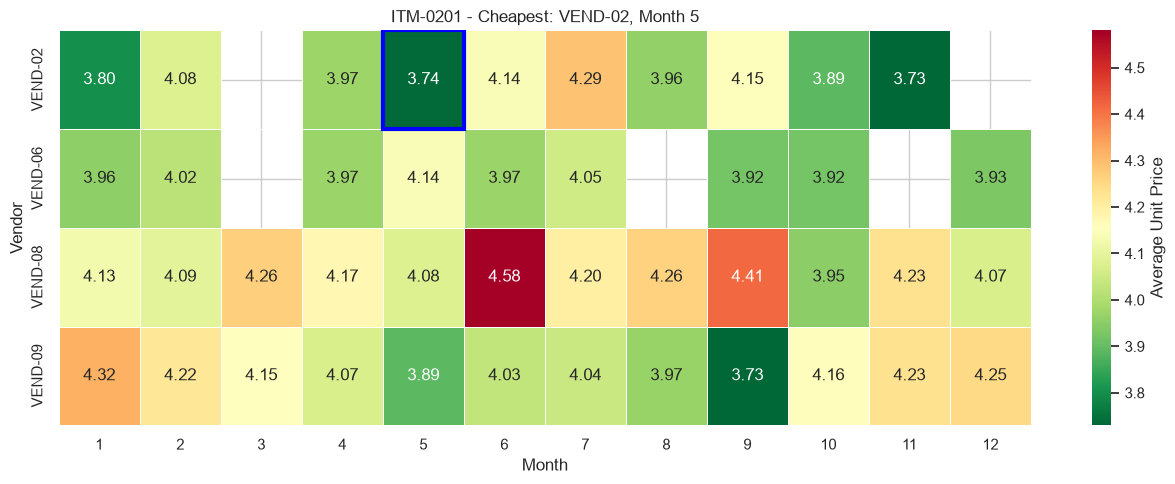

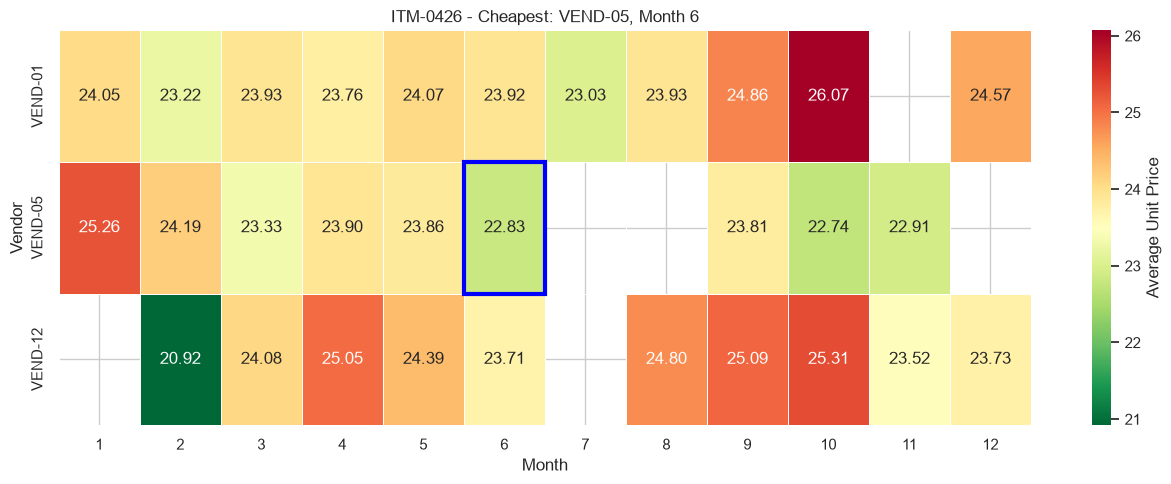

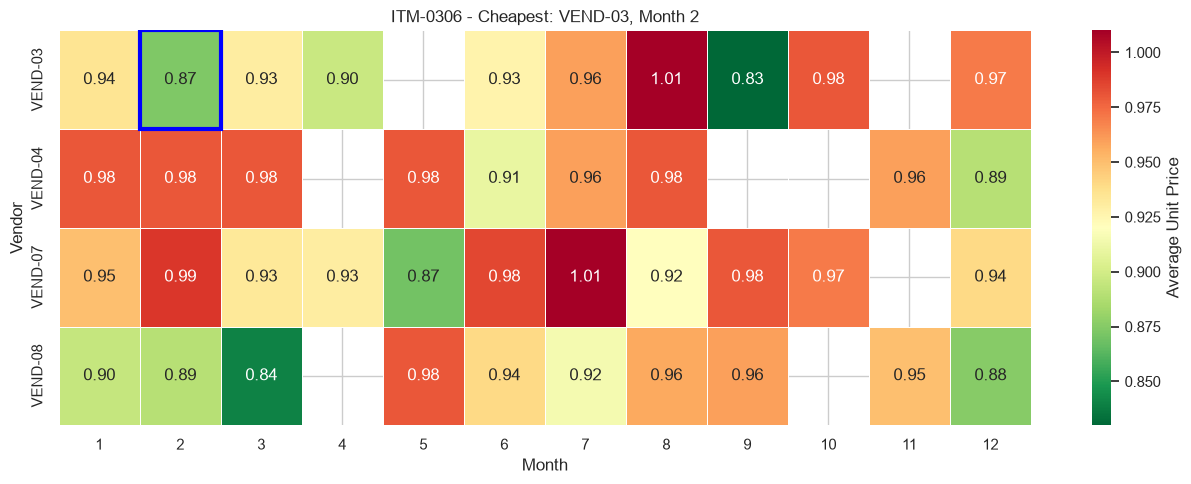

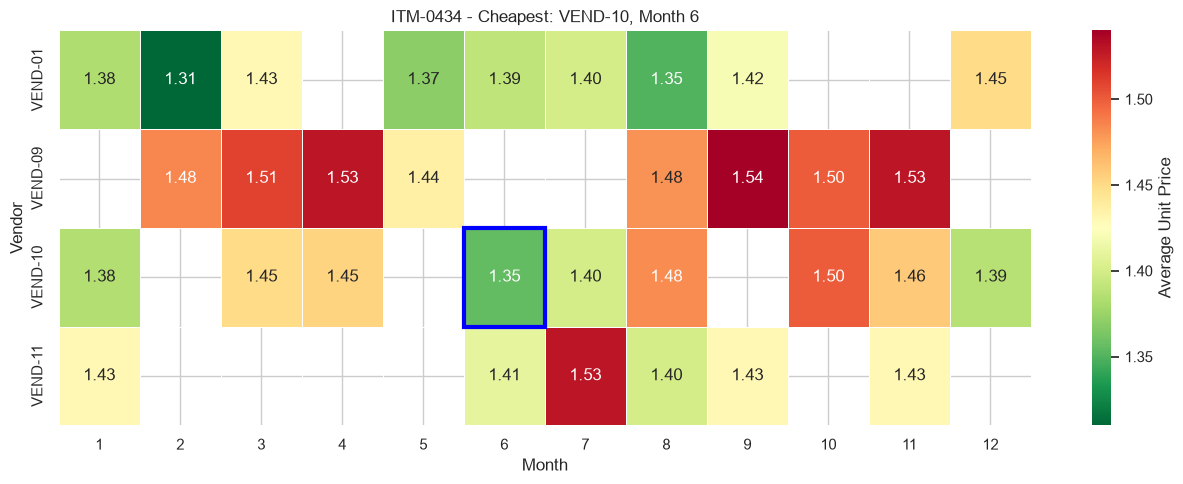

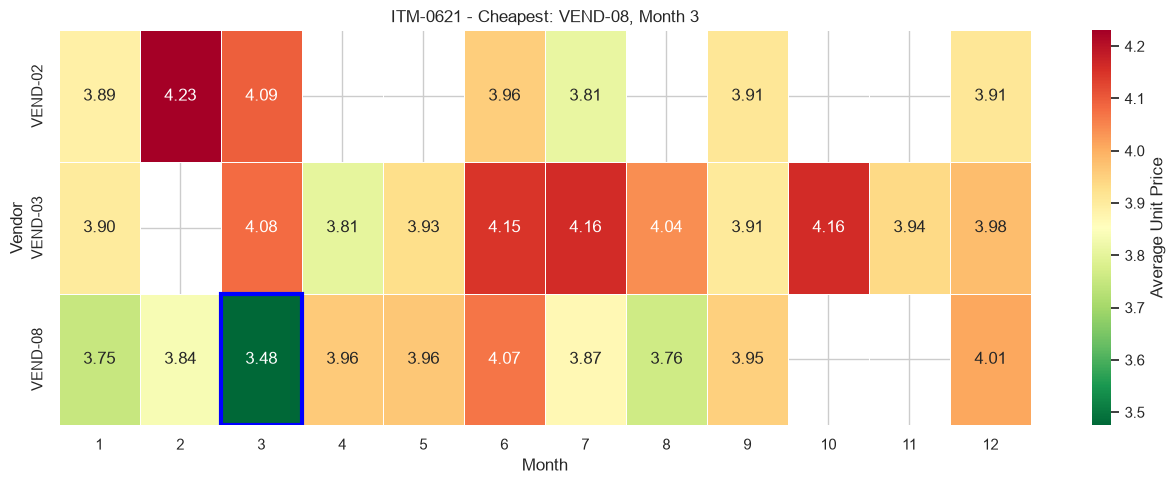

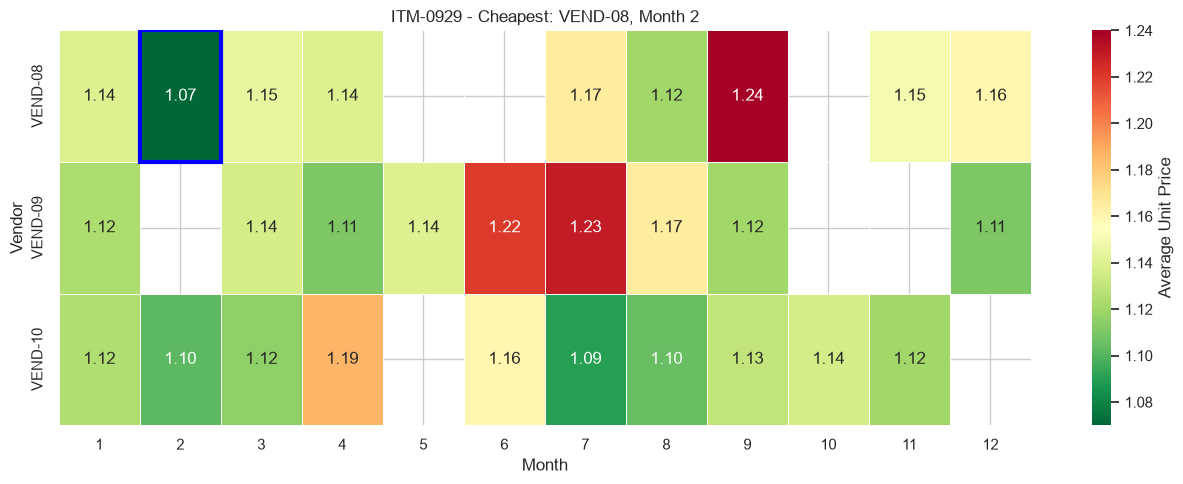

,item_id,vendor_id,month,transactions,average_price,median_price
3,ITM-0201,VEND-02,5,2,3.74,3.74
62,ITM-0237,VEND-04,9,2,2.90,2.90
67,ITM-0306,VEND-03,2,3,0.87,0.87
122,ITM-0426,VEND-05,6,2,22.83,22.83
154,ITM-0433,VEND-05,11,3,1.04,1.05
198,ITM-0434,VEND-10,6,2,1.36,1.36
213,ITM-0612,VEND-05,4,2,3.64,3.64
263,ITM-0621,VEND-08,3,2,3.48,3.48
272,ITM-0929,VEND-08,2,2,1.07,1.07
302,ITM-1015,VEND-04,6,3,3.86,3.91


In [46]:
# Identify cheapest vendor-month combinations for the top 10 frequently purchased items
top_10_items = company_a_active.groupby("item_id")["po_number"].nunique().nlargest(10).index
top_item_vendor_month = (
    company_a_priced[company_a_priced["item_id"].isin(top_10_items)]
    .assign(order_date=lambda x: pd.to_datetime(x["order_date"]))
    .assign(month=lambda x: x["order_date"].dt.month)
    .groupby(["item_id", "vendor_id", "month"])
    .agg(average_price=("unit_price_paid", "mean"), median_price=("unit_price_paid", "median"), transactions=("unit_price_paid", "count"))
    .reset_index()
)

valid_combinations = top_item_vendor_month[top_item_vendor_month["transactions"] >= 2].copy()
cheapest_vendor_month = valid_combinations.loc[valid_combinations.groupby("item_id")["average_price"].idxmin()].copy()

for item in top_10_items:
    item_data = top_item_vendor_month[top_item_vendor_month["item_id"] == item]
    price_pivot = item_data.pivot(index="vendor_id", columns="month", values="average_price")
    if price_pivot.empty:
        continue
    fig, ax = plt.subplots(figsize=(13, 5))
    sns.heatmap(price_pivot, annot=True, fmt=".2f", cmap="RdYlGn_r", linewidths=0.5, ax=ax, cbar_kws={"label": "Average Unit Price"})
    best = cheapest_vendor_month[cheapest_vendor_month["item_id"] == item]
    if not best.empty:
        best_vendor = best["vendor_id"].iloc[0]
        best_month = int(best["month"].iloc[0])
        ax.add_patch(plt.Rectangle((list(price_pivot.columns).index(best_month), list(price_pivot.index).index(best_vendor)), 1, 1, fill=False, edgecolor="blue", linewidth=3))
        ax.set_title(f"{item} - Cheapest: {best_vendor}, Month {best_month}")
    else:
        ax.set_title(f"{item} - No combination with sufficient history")
    ax.set_xlabel("Month")
    ax.set_ylabel("Vendor")
    plt.tight_layout()
    fig.savefig(CHARTS_DIR / f"{item}_vendor_month_price_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    
display(cheapest_vendor_month[["item_id", "vendor_id", "month", "transactions", "average_price", "median_price"]].sort_values("item_id").round(2))

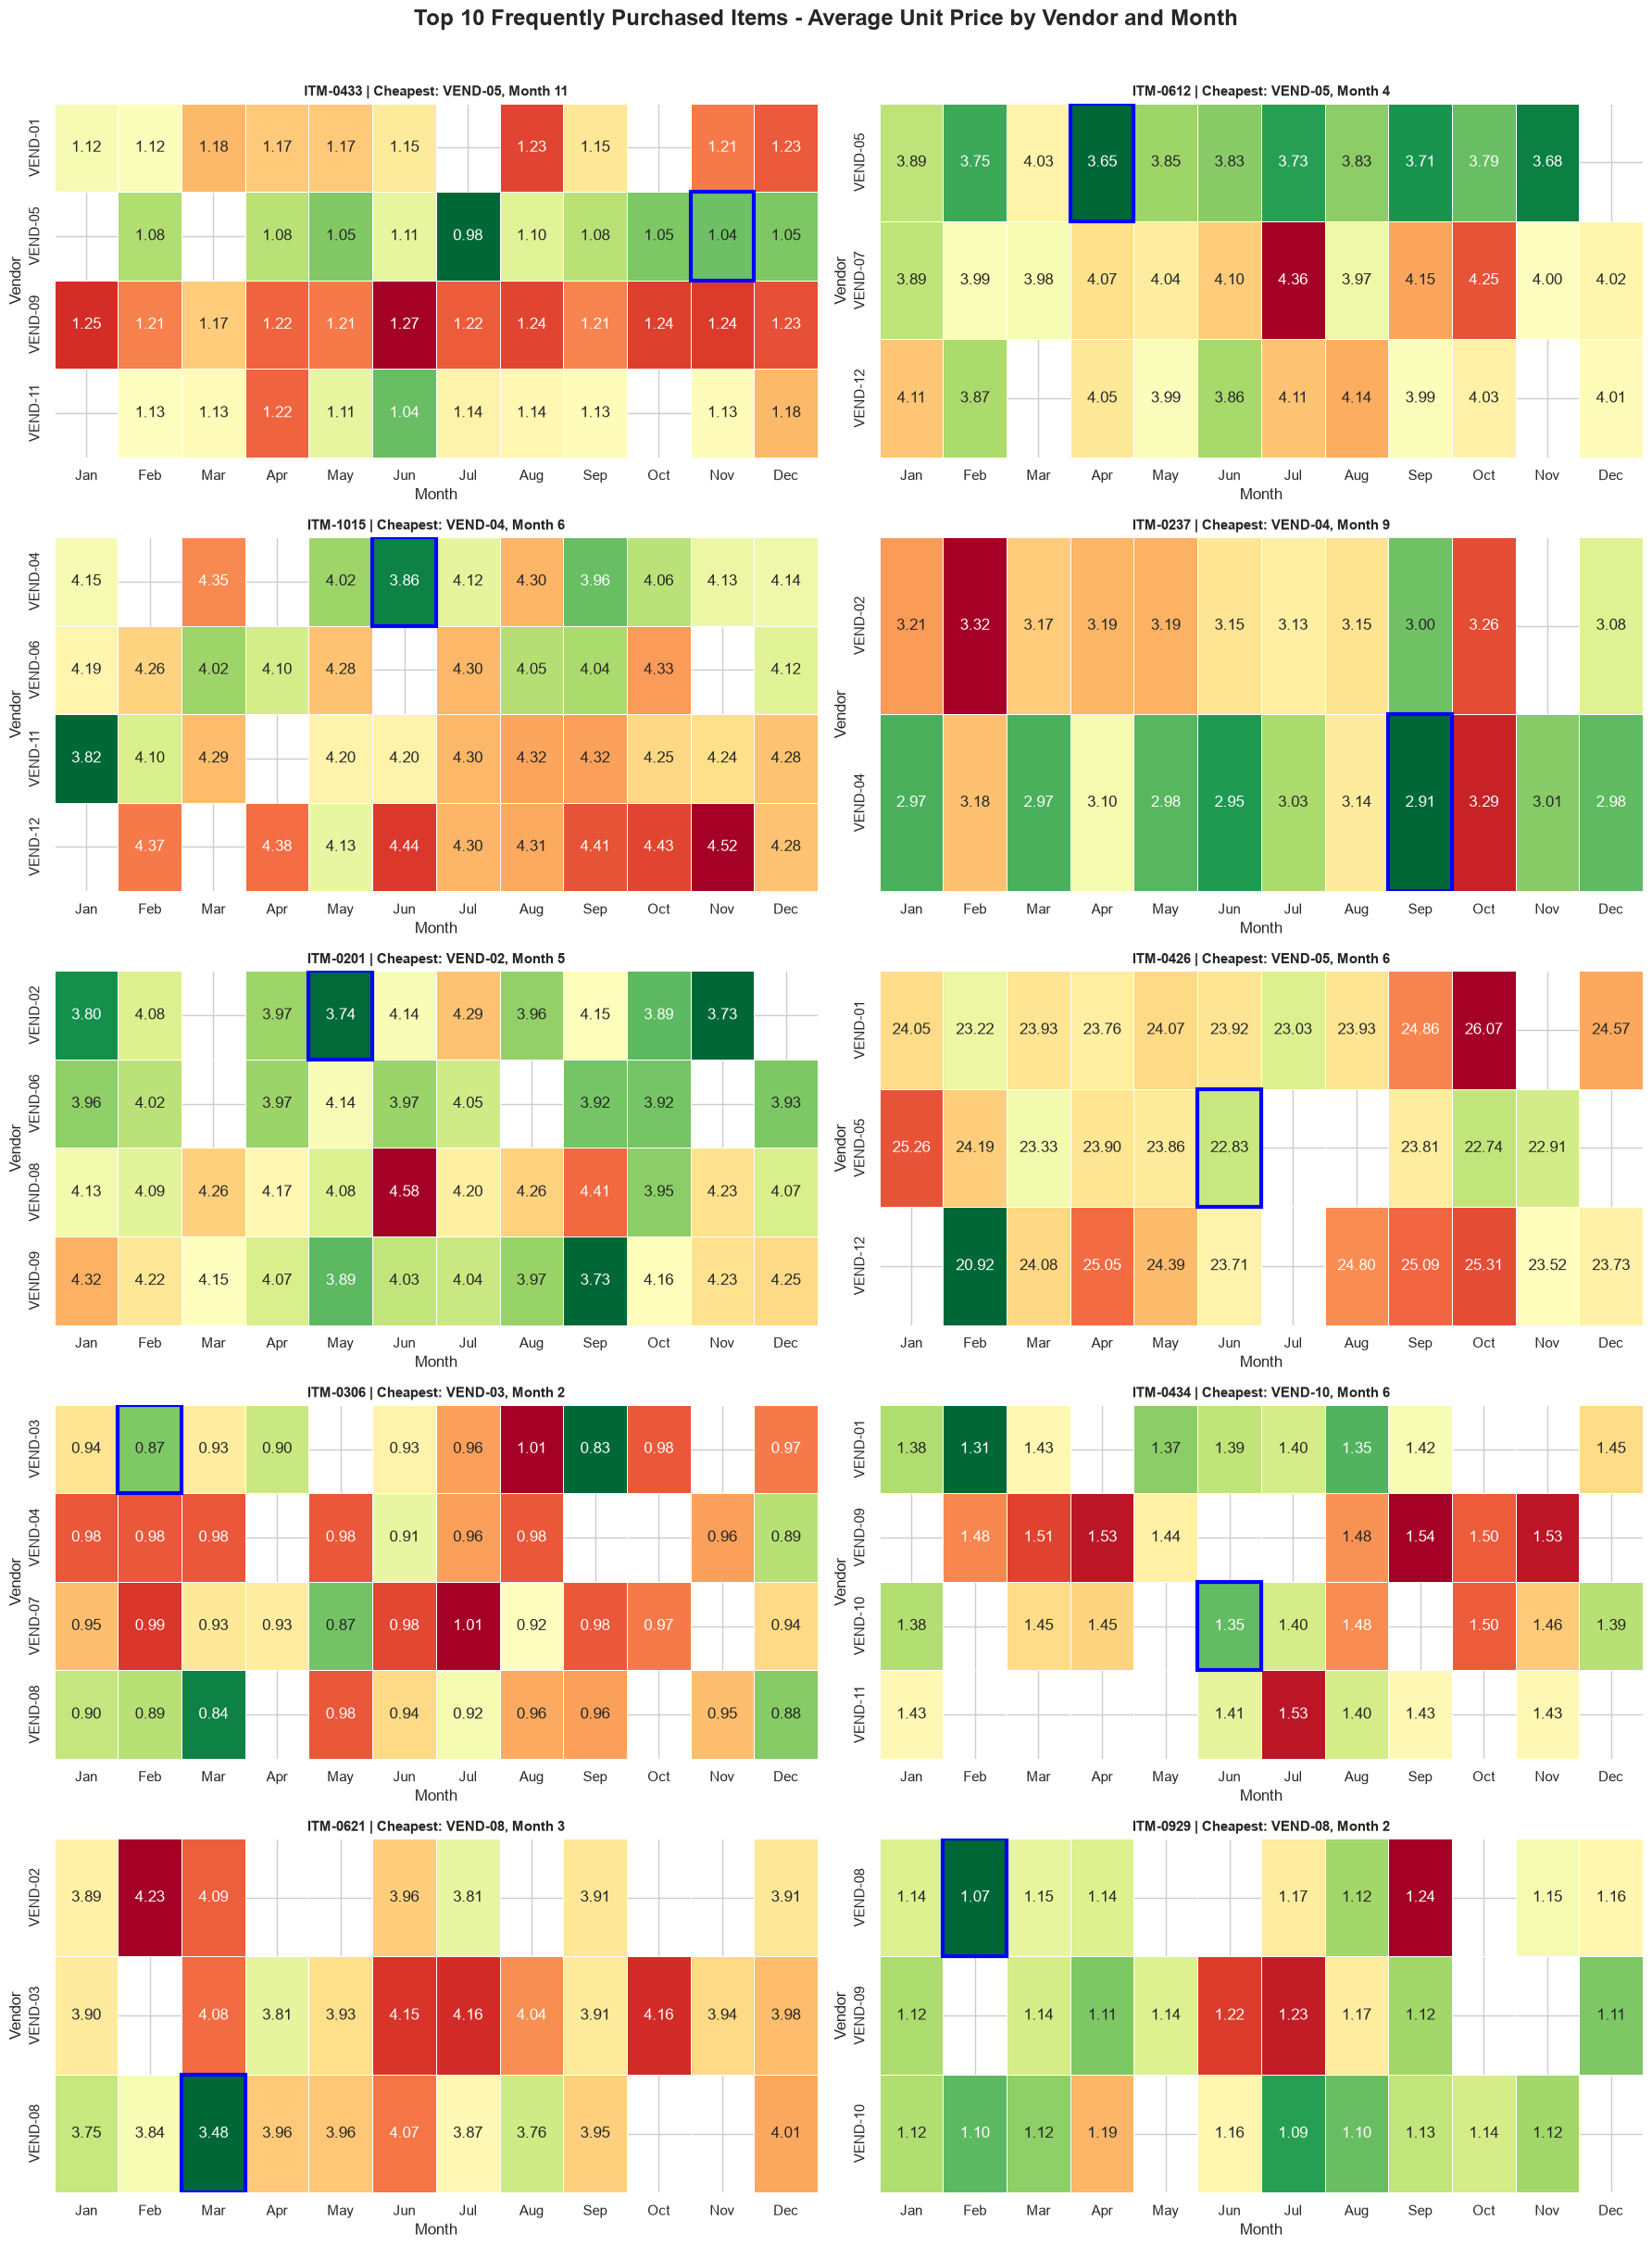

,item_id,vendor_id,month,transactions,average_price,median_price
3,ITM-0201,VEND-02,5,2,3.74,3.74
62,ITM-0237,VEND-04,9,2,2.90,2.90
67,ITM-0306,VEND-03,2,3,0.87,0.87
122,ITM-0426,VEND-05,6,2,22.83,22.83
154,ITM-0433,VEND-05,11,3,1.04,1.05
198,ITM-0434,VEND-10,6,2,1.36,1.36
213,ITM-0612,VEND-05,4,2,3.64,3.64
263,ITM-0621,VEND-08,3,2,3.48,3.48
272,ITM-0929,VEND-08,2,2,1.07,1.07
302,ITM-1015,VEND-04,6,3,3.86,3.91


In [47]:
# Identify cheapest vendor-month combinations for the top 10 items
top_10_items = (
    company_a_active.groupby("item_id")["po_number"]
    .nunique()
    .nlargest(10)
    .index
)

top_item_vendor_month = (
    company_a_priced[
        company_a_priced["item_id"].isin(top_10_items)
    ]
    .assign(order_date=lambda x: pd.to_datetime(x["order_date"]))
    .assign(month=lambda x: x["order_date"].dt.month)
    .groupby(["item_id", "vendor_id", "month"])
    .agg(
        average_price=("unit_price_paid", "mean"),
        median_price=("unit_price_paid", "median"),
        transactions=("unit_price_paid", "count")
    )
    .reset_index()
)

# Require at least two transactions per combination
valid_combinations = top_item_vendor_month[
    top_item_vendor_month["transactions"] >= 2
].copy()

# Find cheapest vendor-month combination for each item
cheapest_vendor_month = (
    valid_combinations.loc[
        valid_combinations.groupby("item_id")["average_price"].idxmin()
    ].copy()
)

# Create one figure containing all 10 item heatmaps
fig, axes = plt.subplots(
    5, 2,
    figsize=(18, 24)
)

axes = axes.flatten()

for i, item in enumerate(top_10_items):

    ax = axes[i]

    item_data = top_item_vendor_month[
        top_item_vendor_month["item_id"] == item
    ]

    price_pivot = item_data.pivot(
        index="vendor_id",
        columns="month",
        values="average_price"
    ).reindex(columns=range(1, 13))

    if price_pivot.dropna(how="all").empty:
        ax.set_title(f"{item} - No price history")
        ax.axis("off")
        continue

    sns.heatmap(
        price_pivot,
        annot=True,
        fmt=".2f",
        cmap="RdYlGn_r",
        linewidths=0.5,
        ax=ax,
        cbar=False,
        mask=price_pivot.isna()
    )

    # Highlight cheapest vendor-month combination
    best = cheapest_vendor_month[
        cheapest_vendor_month["item_id"] == item
    ]

    if not best.empty:
        best_vendor = best["vendor_id"].iloc[0]
        best_month = int(best["month"].iloc[0])

        if best_month in price_pivot.columns:
            row = price_pivot.index.get_loc(best_vendor)
            col = price_pivot.columns.get_loc(best_month)

            ax.add_patch(
                plt.Rectangle(
                    (col, row),
                    1, 1,
                    fill=False,
                    edgecolor="blue",
                    linewidth=3
                )
            )

        ax.set_title(
            f"{item} | Cheapest: {best_vendor}, "
            f"Month {best_month}",
            fontsize=11,
            fontweight="bold"
        )
    else:
        ax.set_title(
            f"{item} | No combination with sufficient history"
        )

    ax.set_xlabel("Month")
    ax.set_ylabel("Vendor")

    ax.set_xticklabels(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
        rotation=0
    )

# Overall title
fig.suptitle(
    "Top 10 Frequently Purchased Items - "
    "Average Unit Price by Vendor and Month",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

fig.savefig(
    CHARTS_DIR / "top10_items_vendor_month_combined.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Display cheapest combinations
display(
    cheapest_vendor_month[
        [
            "item_id",
            "vendor_id",
            "month",
            "transactions",
            "average_price",
            "median_price"
        ]
    ]
    .sort_values("item_id")
    .round(2)
)


In [48]:
# Identify lowest and highest monthly prices and calculate price variation for the top 10 items
monthly_price_summary = (
    top_10_monthly_prices.sort_values("average_price")
    .groupby("item_id")
    .agg(cheapest_month=("month", "first"),
         lowest_price=("average_price", "first"),
         highest_month=("month", "last"),
         highest_price=("average_price", "last"))
    .reset_index()
)

monthly_price_summary["price_difference"] = (
    monthly_price_summary["highest_price"] - monthly_price_summary["lowest_price"]
)
monthly_price_summary["price_variation_pct"] = (
    monthly_price_summary["price_difference"] / monthly_price_summary["lowest_price"] * 100
)

display(monthly_price_summary)

,item_id,cheapest_month,lowest_price,highest_month,highest_price,price_difference,price_variation_pct
0,ITM-0201,5,3.94,3,4.21,0.27,6.76
1,ITM-0237,9,2.95,10,3.27,0.32,10.92
2,ITM-0306,4,0.91,10,0.98,0.07,8.07
3,ITM-0426,2,22.78,10,24.95,2.17,9.52
4,ITM-0433,2,1.14,1,1.21,0.07,6.05
5,ITM-0434,6,1.39,10,1.50,0.11,8.30
6,ITM-0612,11,3.82,7,4.16,0.35,9.06
7,ITM-0621,8,3.83,10,4.16,0.33,8.55
8,ITM-0929,2,1.09,6,1.18,0.09,8.09
9,ITM-1015,6,4.12,8,4.29,0.17,4.05


In [49]:
# Identify cheapest and most expensive vendor-month combinations for the top 10 items
monthly_price_summary = (
    top_item_vendor_month[top_item_vendor_month["transactions"] >= 2]
    .sort_values("average_price")
    .groupby("item_id")
    .agg(cheapest_vendor=("vendor_id", "first"),
         cheapest_month=("month", "first"),
         lowest_price=("average_price", "first"),
         highest_vendor=("vendor_id", "last"),
         highest_month=("month", "last"),
         highest_price=("average_price", "last"),
         cheapest_transactions=("transactions", "first"),
         highest_transactions=("transactions", "last"))
    .reset_index()
)
monthly_price_summary["price_difference"] = monthly_price_summary["highest_price"] - monthly_price_summary["lowest_price"]
monthly_price_summary["price_variation_pct"] = monthly_price_summary["price_difference"] / monthly_price_summary["lowest_price"] * 100
display(monthly_price_summary.round(2))

,item_id,cheapest_vendor,cheapest_month,lowest_price,highest_vendor,highest_month,highest_price,cheapest_transactions,highest_transactions,price_difference,price_variation_pct
0,ITM-0201,VEND-02,5,3.74,VEND-08,9,4.41,2,2,0.68,18.21
1,ITM-0237,VEND-04,9,2.90,VEND-04,10,3.29,2,2,0.38,13.25
2,ITM-0306,VEND-03,2,0.87,VEND-07,6,0.98,3,2,0.11,12.79
3,ITM-0426,VEND-05,6,22.83,VEND-12,10,25.31,2,3,2.48,10.85
4,ITM-0433,VEND-05,11,1.04,VEND-09,6,1.27,3,2,0.23,22.20
5,ITM-0434,VEND-10,6,1.36,VEND-09,4,1.53,2,2,0.18,12.92
6,ITM-0612,VEND-05,4,3.64,VEND-07,7,4.36,2,3,0.71,19.52
7,ITM-0621,VEND-08,3,3.48,VEND-03,7,4.16,2,5,0.68,19.71
8,ITM-0929,VEND-08,2,1.07,VEND-10,4,1.19,2,3,0.12,10.90
9,ITM-1015,VEND-04,6,3.86,VEND-12,10,4.43,3,3,0.57,14.68


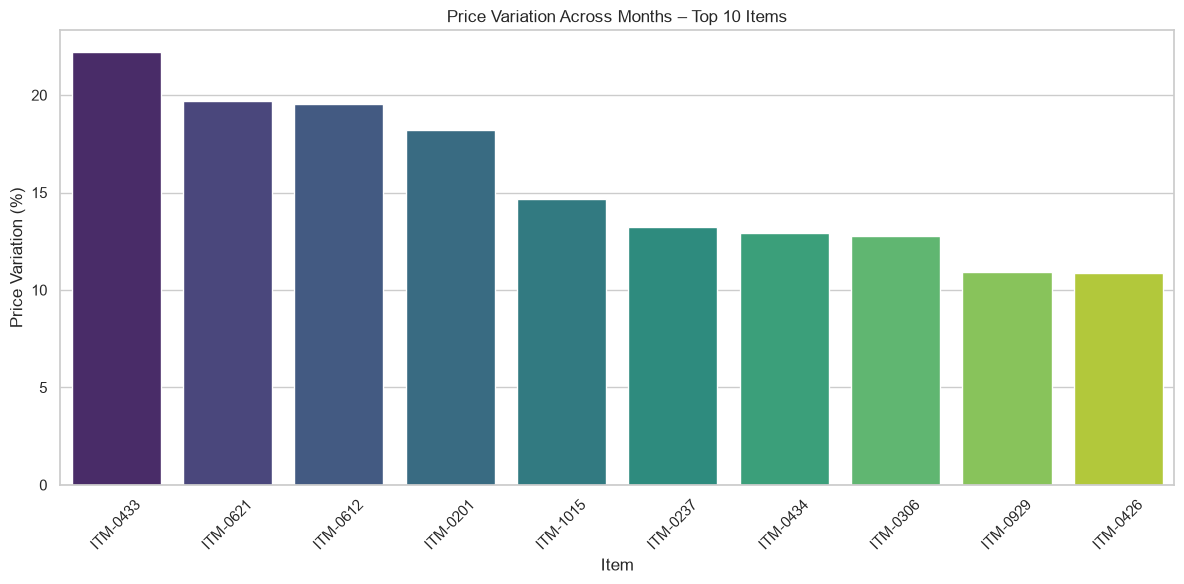

In [50]:
# Visualize monthly price variation across the top 10 frequently purchased items
plt.figure(figsize=(12, 6))
sns.barplot(
    data=monthly_price_summary.sort_values("price_variation_pct", ascending=False),
    x="item_id", y="price_variation_pct", hue="item_id",
    palette="viridis", legend=False
)

plt.title("Price Variation Across Months – Top 10 Items")
plt.xlabel("Item")
plt.ylabel("Price Variation (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top10_items_monthly_price_variation.png", dpi=300, bbox_inches="tight")
plt.show()

In [51]:
# Analyse yearly monthly average prices for the top 10 frequently purchased items
top_10_yearly_monthly = (
    company_a_priced[company_a_priced["item_id"].isin(top_10_items)]
    .assign(year=lambda x: x["order_date"].dt.year,
            month=lambda x: x["order_date"].dt.month)
    .groupby(["item_id", "year", "month"])
    .agg(average_price=("unit_price_paid", "mean"),
         transactions=("po_number", "nunique"))
    .reset_index()
    .sort_values(["item_id", "year", "month"])
)

display(top_10_yearly_monthly)

,item_id,year,month,average_price,transactions
0,ITM-0201,2024,1,4.06,2
1,ITM-0201,2024,2,4.05,4
2,ITM-0201,2024,3,4.15,2
3,ITM-0201,2024,4,3.93,2
4,ITM-0201,2024,5,3.64,2
...,...,...,...,...,...
287,ITM-1015,2026,2,4.38,3
288,ITM-1015,2026,3,4.40,2
289,ITM-1015,2026,6,4.34,2
290,ITM-1015,2026,7,4.25,8


In [52]:
# Prepare yearly monthly average prices for the top 10 frequently purchased items
company_a_priced["order_date"] = pd.to_datetime(company_a_priced["order_date"])

monthly_item_prices = (
    company_a_priced[company_a_priced["item_id"].isin(top_10_items)]
    .assign(year=lambda x: x["order_date"].dt.year,
            month=lambda x: x["order_date"].dt.month)
    .groupby(["item_id", "year", "month"])
    .agg(average_price=("unit_price_paid", "mean"),
         transactions=("po_number", "count"))
    .reset_index()
    .sort_values(["item_id", "year", "month"])
)

monthly_item_prices["average_price"] = monthly_item_prices["average_price"].round(2)

display(monthly_item_prices)

,item_id,year,month,average_price,transactions
0,ITM-0201,2024,1,4.06,2
1,ITM-0201,2024,2,4.06,4
2,ITM-0201,2024,3,4.15,2
3,ITM-0201,2024,4,3.93,2
4,ITM-0201,2024,5,3.64,2
...,...,...,...,...,...
287,ITM-1015,2026,2,4.38,3
288,ITM-1015,2026,3,4.40,2
289,ITM-1015,2026,6,4.34,2
290,ITM-1015,2026,7,4.25,8


In [53]:
# Compare yearly average unit prices and transaction volumes for the top 10 items
yearly_comparison = (
    monthly_item_prices.groupby(["item_id", "year"])
    .agg(average_price=("average_price", "mean"),
         transactions=("transactions", "sum"))
    .reset_index()
    .sort_values(["item_id", "year"])
)

yearly_comparison["average_price"] = yearly_comparison["average_price"].round(2)
display(yearly_comparison)

,item_id,year,average_price,transactions
0,ITM-0201,2024,3.97,30
1,ITM-0201,2025,4.11,29
2,ITM-0201,2026,4.23,23
3,ITM-0237,2024,3.03,32
4,ITM-0237,2025,3.09,31
5,ITM-0237,2026,3.19,22
6,ITM-0306,2024,0.89,16
7,ITM-0306,2025,0.94,37
8,ITM-0306,2026,0.98,14
9,ITM-0426,2024,23.25,26


In [54]:
# Calculate year-over-year percentage changes in average unit prices for the top 10 items
yearly_comparison = yearly_comparison.sort_values(["item_id", "year"])
yearly_comparison["price_change_pct"] = (
    yearly_comparison.groupby("item_id")["average_price"].pct_change() * 100
)

display(yearly_comparison)

,item_id,year,average_price,transactions,price_change_pct
0,ITM-0201,2024,3.97,30,NaN
1,ITM-0201,2025,4.11,29,3.53
2,ITM-0201,2026,4.23,23,2.92
3,ITM-0237,2024,3.03,32,NaN
4,ITM-0237,2025,3.09,31,1.98
5,ITM-0237,2026,3.19,22,3.24
6,ITM-0306,2024,0.89,16,NaN
7,ITM-0306,2025,0.94,37,5.62
8,ITM-0306,2026,0.98,14,4.26
9,ITM-0426,2024,23.25,26,NaN


In [55]:
# Rank items by year-over-year percentage price changes
latest_changes = (
    yearly_comparison.dropna(subset=["price_change_pct"])
    .sort_values("price_change_pct", ascending=False)
)


# Export year-over-year item price changes to outputs/metrics
latest_changes.to_csv(METRICS_DIR / "latest_item_price_changes.csv", index=False)
display(latest_changes)

,item_id,year,average_price,transactions,price_change_pct
7,ITM-0306,2025,0.94,37,5.62
20,ITM-0612,2026,4.13,32,4.56
28,ITM-1015,2025,4.23,38,4.44
10,ITM-0426,2025,24.26,24,4.34
8,ITM-0306,2026,0.98,14,4.26
22,ITM-0621,2025,3.98,28,4.19
1,ITM-0201,2025,4.11,29,3.53
26,ITM-0929,2026,1.18,13,3.51
17,ITM-0434,2026,1.48,10,3.50
5,ITM-0237,2026,3.19,22,3.24


In [56]:
# Classify monthly unit price trends for the top 10 frequently purchased items
trend_results = []

for item, data in monthly_item_prices.groupby("item_id"):
    data = data.assign(date=pd.to_datetime(dict(year=data["year"], month=data["month"], day=1))).sort_values("date")
    x, y = np.arange(len(data)), data["average_price"].to_numpy()
    if len(data) < 2 or np.isnan(y).any() or np.isclose(y.mean(), 0):
        continue
    slope = np.polyfit(x, y, 1)[0]
    monthly_trend_pct = slope / y.mean() * 100
    correlation = np.corrcoef(x, y)[0, 1]
    trend = ("Increasing" if monthly_trend_pct > 0.15 and correlation > 0.4
             else "Decreasing" if monthly_trend_pct < -0.15 and correlation < -0.4
             else "Stable" if abs(monthly_trend_pct) <= 0.15
             else "Fluctuating")
    trend_results.append({
        "item_id": item,
        "average_price": round(y.mean(), 2),
        "monthly_change": round(slope, 4),
        "monthly_trend_pct": round(monthly_trend_pct, 3),
        "correlation": round(correlation, 3),
        "trend": trend
    })

trend_summary = pd.DataFrame(trend_results)
display(trend_summary.sort_values("monthly_trend_pct", ascending=False))

,item_id,average_price,monthly_change,monthly_trend_pct,correlation,trend
2,ITM-0306,0.94,0.00,0.49,0.80,Increasing
7,ITM-0621,3.96,0.01,0.37,0.75,Increasing
9,ITM-1015,4.18,0.01,0.34,0.74,Increasing
8,ITM-0929,1.14,0.00,0.30,0.70,Increasing
3,ITM-0426,23.97,0.07,0.29,0.61,Increasing
0,ITM-0201,4.09,0.01,0.27,0.64,Increasing
6,ITM-0612,3.97,0.01,0.27,0.68,Increasing
1,ITM-0237,3.09,0.01,0.24,0.52,Increasing
5,ITM-0434,1.44,0.00,0.23,0.50,Increasing
4,ITM-0433,1.18,0.00,0.20,0.46,Increasing


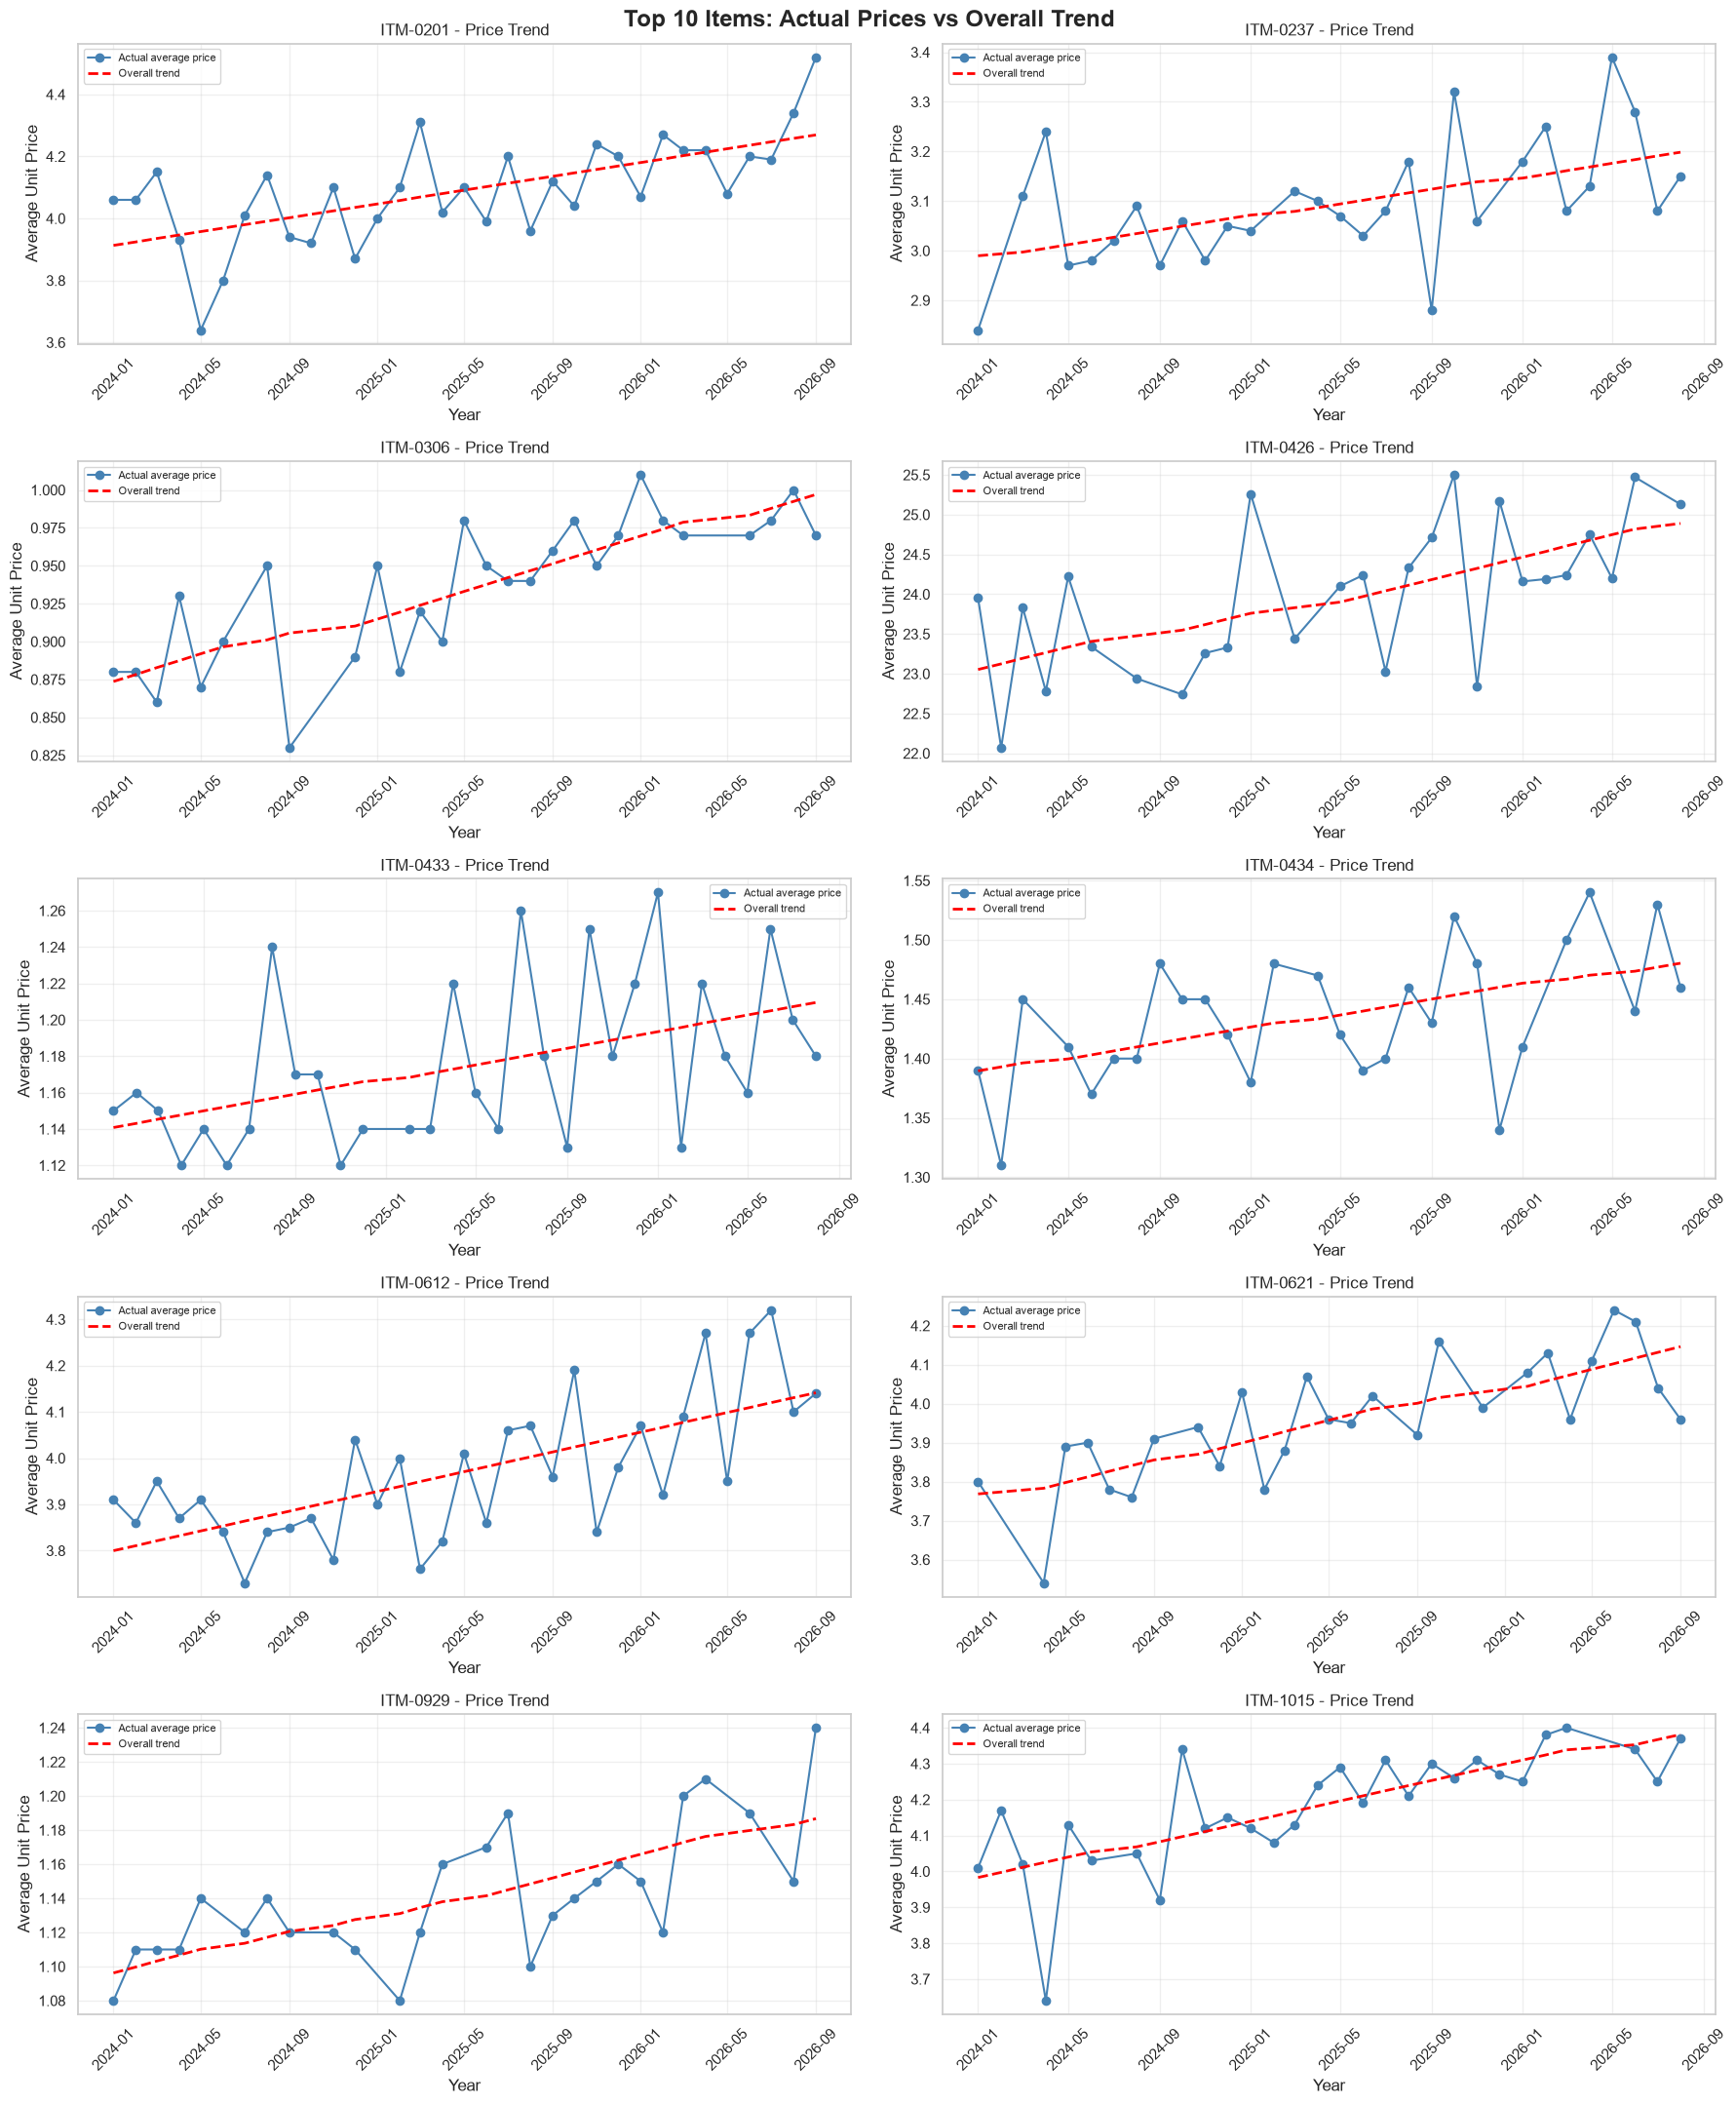

In [57]:
# Visualize actual monthly prices and linear trends for the top 10 frequently purchased items
fig, axes = plt.subplots(5, 2, figsize=(18, 22))
axes = axes.flatten()

for i, item in enumerate(sorted(monthly_item_prices["item_id"].unique())):
    data = monthly_item_prices[monthly_item_prices["item_id"] == item].copy()
    data["date"] = pd.to_datetime(dict(year=data["year"], month=data["month"], day=1))
    data = data.sort_values("date")
    x, y = np.arange(len(data)), data["average_price"].to_numpy()

    if len(data) < 2:
        axes[i].plot(data["date"], y, marker="o", color="steelblue", label="Actual average price")
        axes[i].set_title(f"{item} - Price Trend", fontweight="bold")
        axes[i].set_ylabel("Average Unit Price")
        axes[i].grid(alpha=0.3)
        continue

    slope, intercept = np.polyfit(x, y, 1)
    axes[i].plot(data["date"], y, marker="o", color="steelblue", label="Actual average price")
    axes[i].plot(data["date"], slope * x + intercept, color="red",
                 linestyle="--", linewidth=2, label="Overall trend")
    axes[i].set(title=f"{item} - Price Trend", ylabel="Average Unit Price", xlabel="Year")
    axes[i].grid(alpha=0.3)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].legend(fontsize=8)

plt.suptitle("Top 10 Items: Actual Prices vs Overall Trend", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top10_items_actual_vs_price_trends.png", dpi=300, bbox_inches="tight")
plt.show()

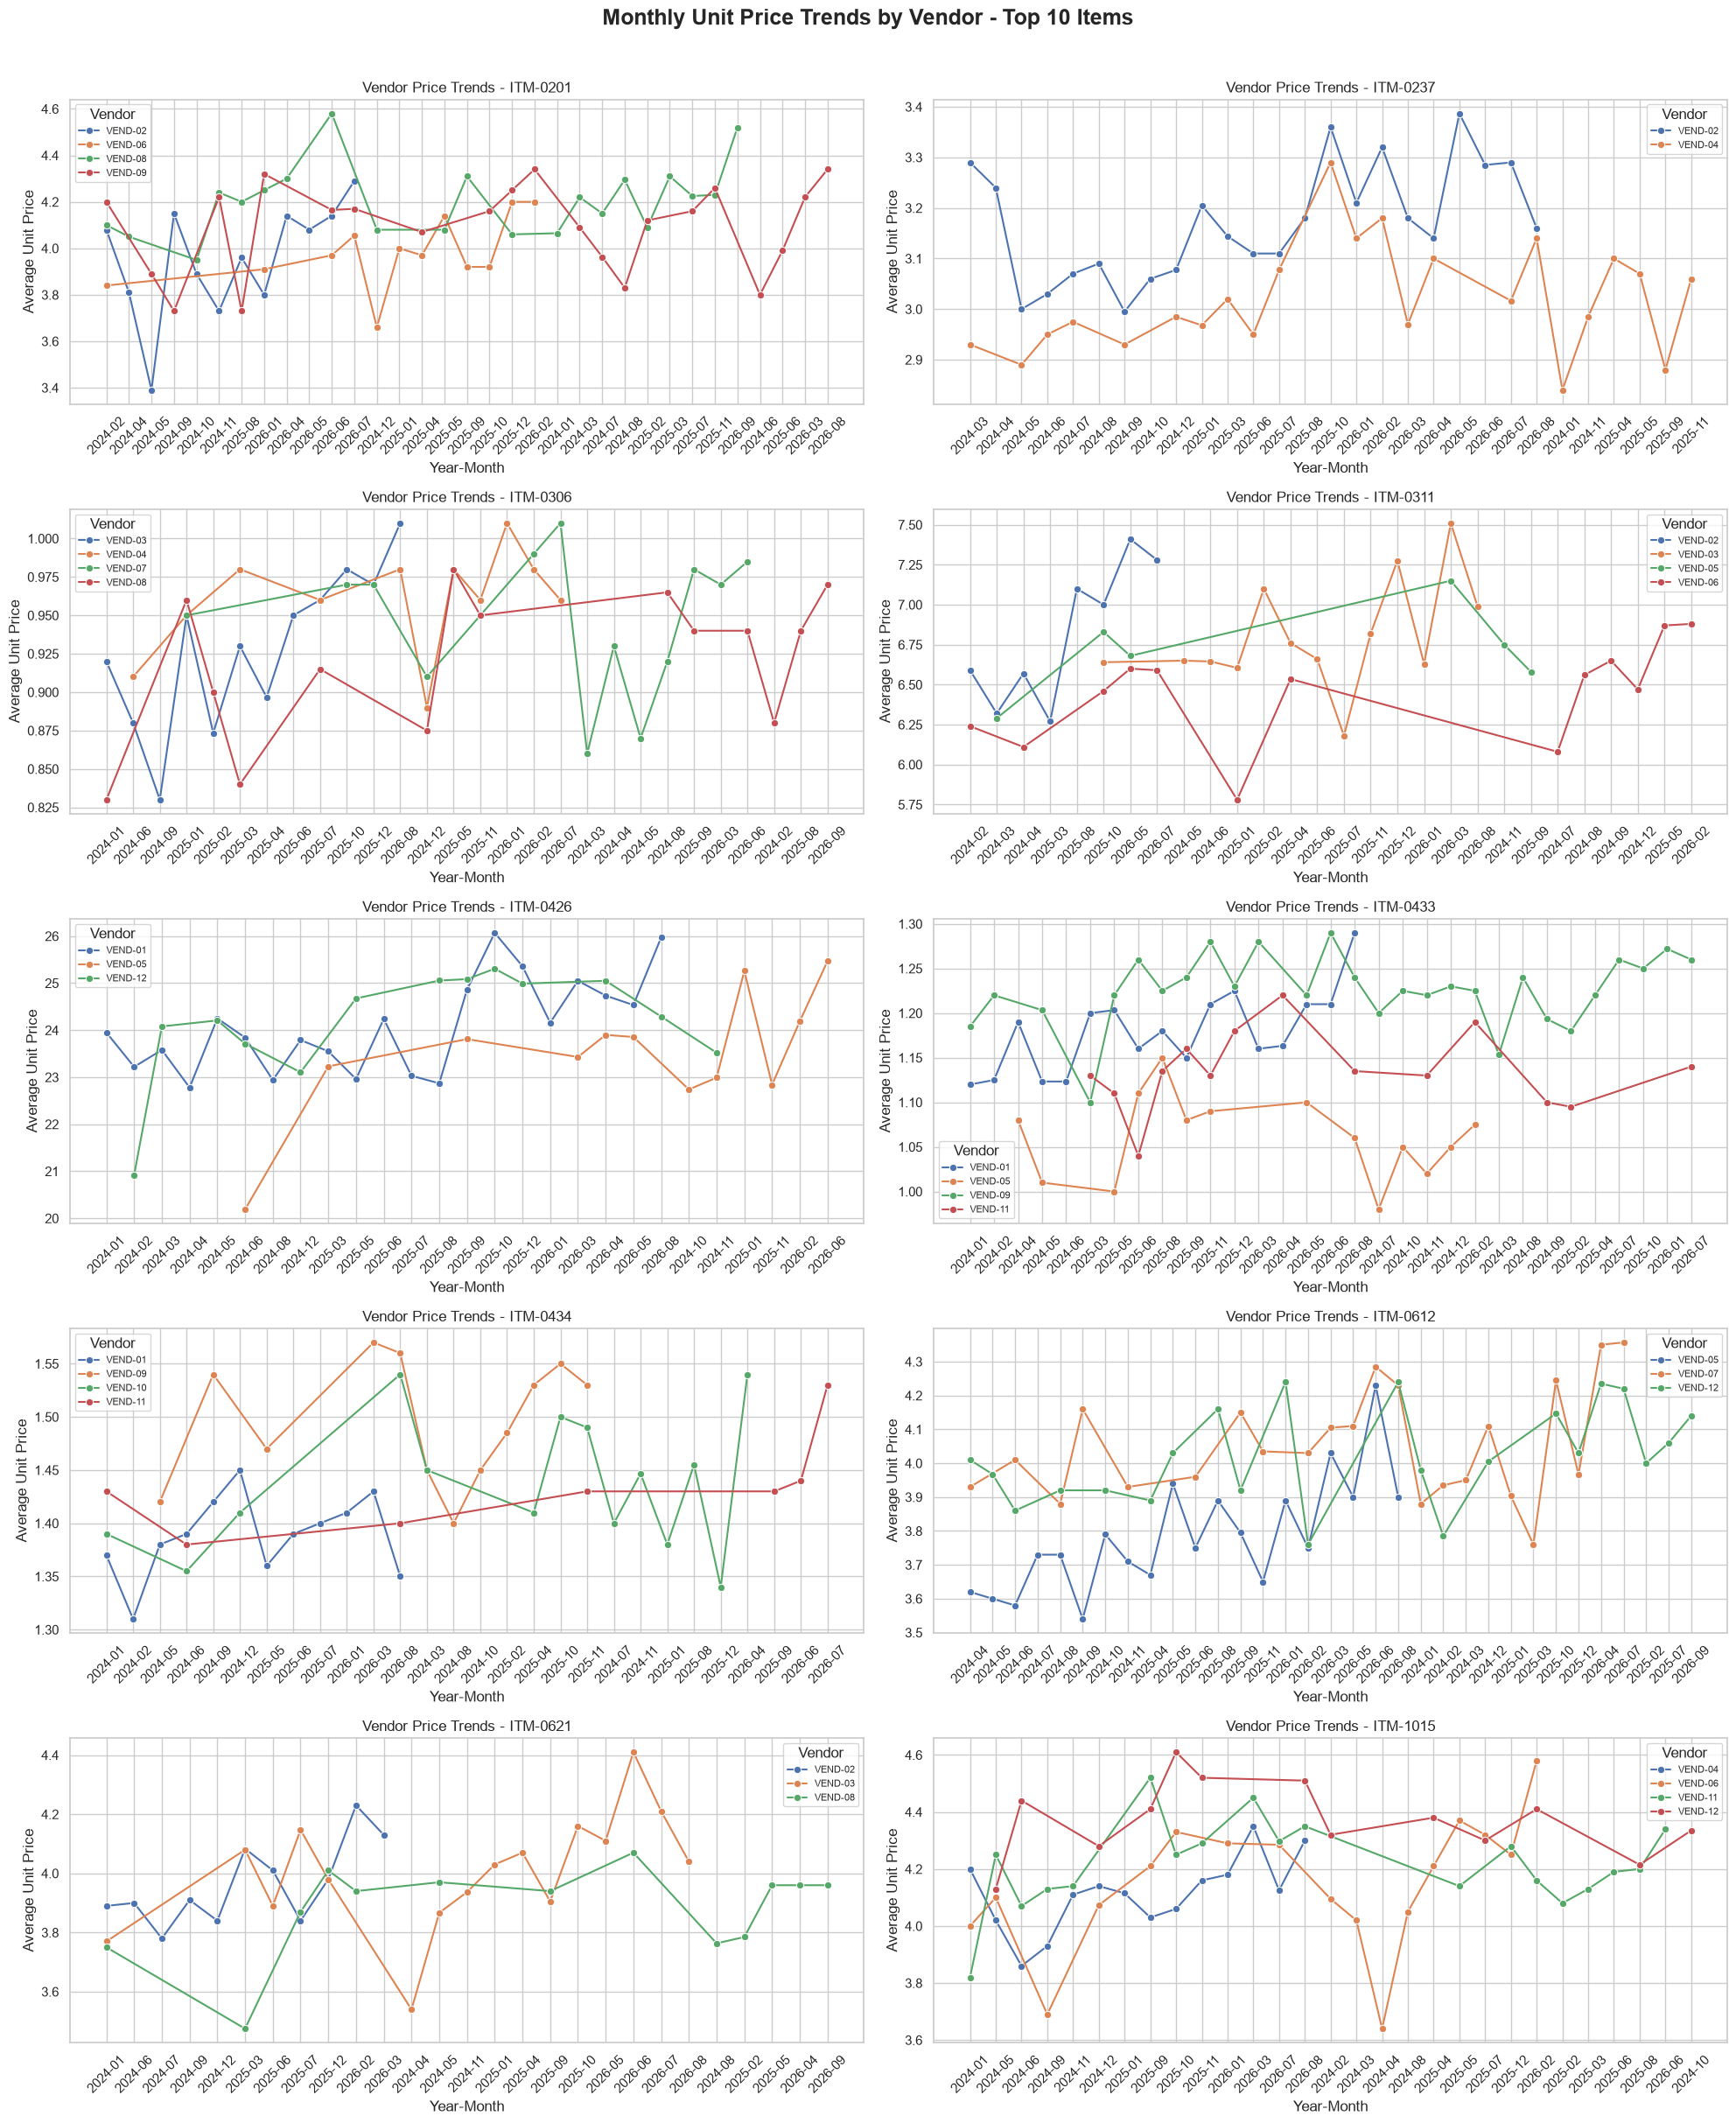

In [58]:
# Visualize monthly vendor price trends for the top 10 items by total quantity purchased
top_10_items = (
    company_a_priced.groupby("item_id")["quantity_ordered"]
    .sum().nlargest(10).index
)

vendor_monthly = (
    company_a_priced[company_a_priced["item_id"].isin(top_10_items)]
    .assign(year_month=lambda x: x["order_date"].dt.to_period("M").astype(str))
    .groupby(["item_id", "vendor_id", "year_month"])
    .agg(average_price=("unit_price_paid", "mean"),
         transactions=("unit_price_paid", "count"))
    .reset_index()
)

fig, axes = plt.subplots(5, 2, figsize=(20, 24))
axes = axes.flatten()
sns.set_style("whitegrid")

for i, item in enumerate(sorted(top_10_items)):
    data = vendor_monthly[vendor_monthly["item_id"] == item]
    sns.lineplot(data=data, x="year_month", y="average_price",
                 hue="vendor_id", marker="o", ax=axes[i])
    axes[i].set(title=f"Vendor Price Trends - {item}",
                xlabel="Year-Month", ylabel="Average Unit Price")
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].legend(title="Vendor", fontsize=8)

plt.suptitle("Monthly Unit Price Trends by Vendor - Top 10 Items",
             fontsize=18, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top10_quantity_items_vendor_monthly_trends.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [59]:
# Calculate monthly average prices by item and vendor for the top 10 frequently purchased items
vendor_monthly_prices = (
    company_a_priced[
        company_a_priced["item_id"].isin(top_10_items)
    ]
    .assign(date=lambda x: pd.to_datetime(x["order_date"], errors="coerce"))
    .dropna(subset=["date", "unit_price_paid"])
    .assign(month=lambda x: x["date"].dt.month)
    .groupby(["item_id", "vendor_id", "month", "date"])
    .agg(average_price=("unit_price_paid", "mean"), transactions=("unit_price_paid", "count"))
    .reset_index()
)

display(vendor_monthly_prices.head())

,item_id,vendor_id,month,date,average_price,transactions
0,ITM-0201,VEND-02,1,2026-01-06,3.80,1
1,ITM-0201,VEND-02,2,2024-02-13,4.08,1
2,ITM-0201,VEND-02,4,2024-04-05,3.81,1
3,ITM-0201,VEND-02,4,2026-04-27,4.14,1
4,ITM-0201,VEND-02,5,2024-05-05,3.39,1


In [60]:
# Analyse monthly vendor price trends for the top 10 frequently purchased items
vendor_trends = []

for (item, vendor), data in vendor_monthly_prices.groupby(["item_id", "vendor_id"]):
    data = data.sort_values("date")
    x = (data["date"].dt.year * 12 + data["date"].dt.month).to_numpy()
    x = x - x.min()
    y = data["average_price"].to_numpy()

    if len(data) < 3 or np.isclose(y.mean(), 0):
        continue

    slope = np.polyfit(x, y, 1)[0]
    correlation = np.corrcoef(x, y)[0, 1]

    vendor_trends.append({
        "item_id": item,
        "vendor_id": vendor,
        "average_price": round(y.mean(), 2),
        "monthly_price_change": round(slope, 4),
        "trend_correlation": round(correlation, 3),
        "observations": len(data)
    })

vendor_trend_summary = (
    pd.DataFrame(vendor_trends)
    .sort_values(["item_id", "monthly_price_change"], ascending=[True, False])
    .reset_index(drop=True)
)

display(vendor_trend_summary)

,item_id,vendor_id,average_price,monthly_price_change,trend_correlation,observations
0,ITM-0201,VEND-02,3.98,0.01,0.59,13
1,ITM-0201,VEND-09,4.10,0.01,0.57,27
2,ITM-0201,VEND-08,4.20,0.01,0.58,27
3,ITM-0201,VEND-06,3.99,0.01,0.50,13
4,ITM-0237,VEND-02,3.16,0.01,0.48,45
5,ITM-0237,VEND-04,3.02,0.01,0.50,38
6,ITM-0306,VEND-03,0.93,0.00,0.71,18
7,ITM-0306,VEND-07,0.95,0.00,0.86,16
8,ITM-0306,VEND-04,0.96,0.00,0.63,11
9,ITM-0306,VEND-08,0.92,0.00,0.49,17


In [61]:
# Rank Company A vendors by item pricing and assess price consistency and purchasing volume
item_vendor_ranking = (
    company_a_priced.groupby(["item_id", "vendor_id"])
    .agg(average_price=("unit_price_paid", "mean"),
         median_price=("unit_price_paid", "median"),
         price_std=("unit_price_paid", "std"),
         transactions=("unit_price_paid", "count"),
         total_quantity=("quantity_ordered", "sum"))
    .reset_index()
)

item_vendor_ranking["price_rank"] = (
    item_vendor_ranking.groupby("item_id")["average_price"].rank(method="min")
)

item_vendor_ranking["price_cv_pct"] = (
    item_vendor_ranking["price_std"] / item_vendor_ranking["average_price"] * 100
)

display(item_vendor_ranking.sort_values(["item_id", "price_rank"]).round(3))


,item_id,vendor_id,average_price,median_price,price_std,transactions,total_quantity,price_rank,price_cv_pct
0,ITM-0104,VEND-03,60.43,60.43,NaN,1,1,1.00,NaN
1,ITM-0104,VEND-06,62.00,63.08,4.68,6,144,2.00,7.56
2,ITM-0104,VEND-07,65.12,64.31,3.31,3,14,3.00,5.08
3,ITM-0104,VEND-11,67.30,67.30,NaN,1,12,4.00,NaN
5,ITM-0201,VEND-06,3.99,3.97,0.15,13,127,1.00,3.75
...,...,...,...,...,...,...,...,...,...
340,ITM-1020,VEND-11,9.18,9.18,NaN,1,5,3.00,NaN
341,ITM-1021,VEND-02,4.31,4.31,NaN,1,20,1.00,NaN
342,ITM-1021,VEND-09,4.68,4.56,0.18,5,22,2.00,3.84
344,ITM-1022,VEND-11,5.01,5.01,0.49,2,30,1.00,9.73


In [62]:
# Evaluate overall vendor competitiveness using price rankings, supply coverage and price consistency
vendor_competitiveness = (
    item_vendor_ranking.groupby("vendor_id")
    .agg(items_supplied=("item_id", "nunique"),
         average_price_rank=("price_rank", "mean"),
         total_transactions=("transactions", "sum"),
         total_quantity=("total_quantity", "sum"),
         average_price_volatility=("price_cv_pct", "mean"))
    .reset_index()
    .sort_values("average_price_rank")
)

max_rank = vendor_competitiveness["average_price_rank"].max()
vendor_competitiveness["competitiveness_score"] = (
    100 * (1 - (vendor_competitiveness["average_price_rank"] - 1) / (max_rank - 1))
    if max_rank > 1 else 100
)

display(vendor_competitiveness.round(2))

,vendor_id,items_supplied,average_price_rank,total_transactions,total_quantity,average_price_volatility,competitiveness_score
4,VEND-05,34,1.50,159,1364,3.85,72.00
0,VEND-01,27,1.70,172,1433,3.52,60.59
7,VEND-08,29,1.97,181,1286,11.28,45.93
5,VEND-06,33,1.97,152,1442,4.22,45.70
1,VEND-02,33,2.03,184,1519,3.72,42.30
6,VEND-07,32,2.03,198,1453,4.30,42.25
11,VEND-12,19,2.05,188,1464,4.46,41.05
3,VEND-04,27,2.07,153,1254,4.07,39.85
2,VEND-03,29,2.14,192,1845,4.37,36.28
9,VEND-10,23,2.22,222,1689,8.80,31.83


In [63]:
# Estimate potential purchasing savings against the lowest vendor price for each item
benchmark = (
    item_vendor_ranking.groupby("item_id")["average_price"]
    .min()
    .rename("benchmark_price")
)

savings_analysis = item_vendor_ranking.merge(benchmark, on="item_id")
savings_analysis["potential_savings"] = (
    (savings_analysis["average_price"] - savings_analysis["benchmark_price"])
    * savings_analysis["total_quantity"]
)

display(savings_analysis.sort_values("potential_savings", ascending=False).round(2))

,item_id,vendor_id,average_price,median_price,price_std,transactions,total_quantity,price_rank,price_cv_pct,benchmark_price,potential_savings
236,ITM-0902,VEND-10,13.96,4.26,16.70,7,62,4.00,119.66,4.01,616.57
220,ITM-0737,VEND-10,70.02,70.25,2.50,7,98,2.00,3.58,67.65,232.82
1,ITM-0104,VEND-06,62.00,63.08,4.69,6,144,2.00,7.56,60.43,226.32
49,ITM-0250,VEND-09,60.38,61.10,2.39,13,73,4.00,3.96,57.74,192.35
116,ITM-0426,VEND-01,24.00,23.79,1.04,29,331,2.00,4.32,23.52,157.74
...,...,...,...,...,...,...,...,...,...,...,...
302,ITM-0947,VEND-02,0.43,0.43,NaN,1,24,1.00,NaN,0.43,0.00
12,ITM-0219,VEND-07,1.68,1.68,NaN,1,24,1.00,NaN,1.68,0.00
344,ITM-1022,VEND-11,5.02,5.02,0.49,2,30,1.00,9.73,5.02,0.00
10,ITM-0211,VEND-02,12.00,12.00,0.69,2,8,1.00,5.71,12.00,0.00


In [64]:
# Identify the cheapest vendor per item and calculate potential savings against its benchmark price
cheapest_vendor = (
    item_vendor_ranking.sort_values("average_price")
    .groupby("item_id")
    .first()
    .reset_index()[["item_id", "vendor_id", "average_price"]]
    .rename(columns={"vendor_id": "cheapest_vendor",
                     "average_price": "benchmark_price"})
)

savings_analysis = item_vendor_ranking.merge(cheapest_vendor, on="item_id")
savings_analysis["potential_savings"] = (
    (savings_analysis["average_price"] - savings_analysis["benchmark_price"])
    * savings_analysis["total_quantity"]
)

savings_analysis = savings_analysis.sort_values(
    ["item_id", "potential_savings"], ascending=[True, False]
)

display(savings_analysis.round(2))

,item_id,vendor_id,average_price,median_price,price_std,transactions,total_quantity,price_rank,price_cv_pct,cheapest_vendor,benchmark_price,potential_savings
1,ITM-0104,VEND-06,62.00,63.08,4.69,6,144,2.00,7.56,VEND-03,60.43,226.32
3,ITM-0104,VEND-11,67.30,67.30,NaN,1,12,4.00,NaN,VEND-03,60.43,82.44
2,ITM-0104,VEND-07,65.12,64.31,3.31,3,14,3.00,5.08,VEND-03,60.43,65.66
0,ITM-0104,VEND-03,60.43,60.43,NaN,1,1,1.00,NaN,VEND-03,60.43,0.00
7,ITM-0201,VEND-09,4.10,4.12,0.19,28,312,3.00,4.63,VEND-06,3.99,35.37
...,...,...,...,...,...,...,...,...,...,...,...,...
338,ITM-1020,VEND-02,8.20,8.20,0.04,2,14,1.00,0.43,VEND-02,8.20,0.00
342,ITM-1021,VEND-09,4.68,4.56,0.18,5,22,2.00,3.84,VEND-02,4.31,8.05
341,ITM-1021,VEND-02,4.31,4.31,NaN,1,20,1.00,NaN,VEND-02,4.31,0.00
343,ITM-1022,VEND-04,5.02,5.02,NaN,1,50,2.00,NaN,VEND-11,5.02,0.25


In [65]:
# Summarise and export potential purchasing savings by item
item_savings = (
    savings_analysis.groupby("item_id")
    .agg(total_potential_savings=("potential_savings", "sum"),
         vendors=("vendor_id", "nunique"))
    .reset_index()
    .sort_values("total_potential_savings", ascending=False)
)


display(item_savings.round(2))
print("Total potential savings:", round(item_savings["total_potential_savings"].sum(), 2))

,item_id,total_potential_savings,vendors
84,ITM-0902,725.78,4
79,ITM-0737,428.50,4
0,ITM-0104,374.42,4
17,ITM-0250,326.89,4
44,ITM-0426,297.75,3
...,...,...,...
24,ITM-0305,0.00,1
14,ITM-0240,0.00,1
63,ITM-0609,0.00,1
107,ITM-0947,0.00,1


Total potential savings: 4356.89


In [66]:

# Summarise and export cheapest vendors and potential savings by item
item_savings = (
    savings_analysis.groupby("item_id")
    .agg(cheapest_vendor=("cheapest_vendor", "first"),
         benchmark_price=("benchmark_price", "first"),
         total_potential_savings=("potential_savings", "sum"),
         vendors=("vendor_id", "nunique"))
    .reset_index()
    .sort_values("total_potential_savings", ascending=False)
)

item_savings.to_csv(METRICS_DIR / "item_cheapest_vendor_savings.csv", index=False)

display(item_savings.round(2))
print("Total potential savings:", round(item_savings["total_potential_savings"].sum(), 2))


,item_id,cheapest_vendor,benchmark_price,total_potential_savings,vendors
84,ITM-0902,VEND-11,4.01,725.78,4
79,ITM-0737,VEND-07,67.65,428.50,4
0,ITM-0104,VEND-03,60.43,374.42,4
17,ITM-0250,VEND-11,57.74,326.89,4
44,ITM-0426,VEND-05,23.52,297.75,3
...,...,...,...,...,...
24,ITM-0305,VEND-07,41.17,0.00,1
14,ITM-0240,VEND-09,44.09,0.00,1
63,ITM-0609,VEND-04,1.48,0.00,1
107,ITM-0947,VEND-02,0.43,0.00,1


Total potential savings: 4356.89
